In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('/kaggle/input/engage-2-value-from-clicks-to-conversions/train_data.csv')

# Exploratory Data Analysis (EDA)

In [3]:
df.head()

,trafficSource.isTrueDirect,purchaseValue,browser,device.screenResolution,trafficSource.adContent,trafficSource.keyword,screenSize,geoCluster,trafficSource.adwordsClickInfo.slot,device.mobileDeviceBranding,...,device.language,deviceType,userChannel,device.browserVersion,totalHits,device.screenColors,sessionStart,geoNetwork.continent,device.isMobile,new_visits
0,NaN,0.0,Edge,not available in demo dataset,NaN,NaN,medium,Region_2,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Social,not available in demo dataset,1,not available in demo dataset,1500100799,Americas,False,1.0
1,True,0.0,Chrome,not available in demo dataset,NaN,NaN,medium,Region_3,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Direct,not available in demo dataset,1,not available in demo dataset,1495262065,Americas,False,1.0
2,True,0.0,Chrome,not available in demo dataset,NaN,(not provided),medium,Region_2,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Organic Search,not available in demo dataset,6,not available in demo dataset,1508510328,Europe,False,NaN
3,NaN,0.0,Internet Explorer,not available in demo dataset,NaN,NaN,medium,Region_4,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Social,not available in demo dataset,1,not available in demo dataset,1483431838,Asia,False,1.0
4,True,88950000.0,Chrome,not available in demo dataset,NaN,NaN,medium,Region_3,NaN,not available in demo dataset,...,not available in demo dataset,desktop,Direct,not available in demo dataset,66,not available in demo dataset,1475804633,Americas,False,1.0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 116023 entries, 0 to 116022
Data columns (total 52 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   trafficSource.isTrueDirect                    42890 non-null   object 
 1   purchaseValue                                 116023 non-null  float64
 2   browser                                       116023 non-null  object 
 3   device.screenResolution                       116023 non-null  object 
 4   trafficSource.adContent                       2963 non-null    object 
 5   trafficSource.keyword                         44162 non-null   object 
 6   screenSize                                    116023 non-null  object 
 7   geoCluster                                    116023 non-null  object 
 8   trafficSource.adwordsClickInfo.slot           4281 non-null    object 
 9   device.mobileDeviceBranding                   11

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
purchaseValue,116023.0,2.656393e+07,2.051825e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.312950e+10
userId,116023.0,6.109436e+04,3.524076e+04,0.000000e+00,3.060350e+04,6.101400e+04,9.161650e+04,1.222760e+05
gclIdPresent,116023.0,3.701852e-02,1.888080e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
sessionNumber,116023.0,2.691311e+00,1.045161e+01,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,4.470000e+02
totals.visits,116023.0,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
sessionId,116023.0,1.493429e+09,1.528798e+07,1.470035e+09,1.480066e+09,1.491646e+09,1.505079e+09,1.525157e+09
trafficSource.adwordsClickInfo.page,4281.0,1.019622e+00,1.745165e-01,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,5.000000e+00
pageViews,116015.0,8.412352e+00,1.434494e+01,1.000000e+00,1.000000e+00,2.000000e+00,1.000000e+01,4.690000e+02
locationZone,116023.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00,8.000000e+00
totals.bounces,47148.0,1.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00


In [6]:
df.isnull().sum()

trafficSource.isTrueDirect                       73133
purchaseValue                                        0
browser                                              0
device.screenResolution                              0
trafficSource.adContent                         113060
trafficSource.keyword                            71861
screenSize                                           0
geoCluster                                           0
trafficSource.adwordsClickInfo.slot             111742
device.mobileDeviceBranding                          0
device.mobileInputSelector                           0
userId                                               0
trafficSource.campaign                               0
device.mobileDeviceMarketingName                     0
geoNetwork.networkDomain                             0
gclIdPresent                                         0
device.operatingSystemVersion                        0
sessionNumber                                        0
device.fla

In [7]:
def create_new_cols(df: pd.DataFrame) -> pd.DataFrame: 
    df['pageviewsPerSession'] = df['pageViews'] / (df['sessionId'].map(df.groupby('sessionId').size()) + 1e-6)
    user_session_counts = df.groupby('userId')['sessionId'].nunique().reset_index()
    user_session_counts.columns = ['userId', 'userSessionCount']
    df = df.merge(user_session_counts, on='userId', how='left')
    return df

df = create_new_cols(df)


1. ZERO-INFLATION ANALYSIS
----------------------------------------
Total observations: 116,023
Zero purchases: 92,038 (79.33%)
Non-zero purchases: 23,985 (20.67%)
High Zero-Inflation detected.

Non-zero purchase value statistics:
Mean: $128498097.14
Median: $47700000.00
Std: $436529692.72
Min: $10000.00
Max: $23129500000.00

2. TARGET VARIABLE VISUALIZATION
-----------------------------------


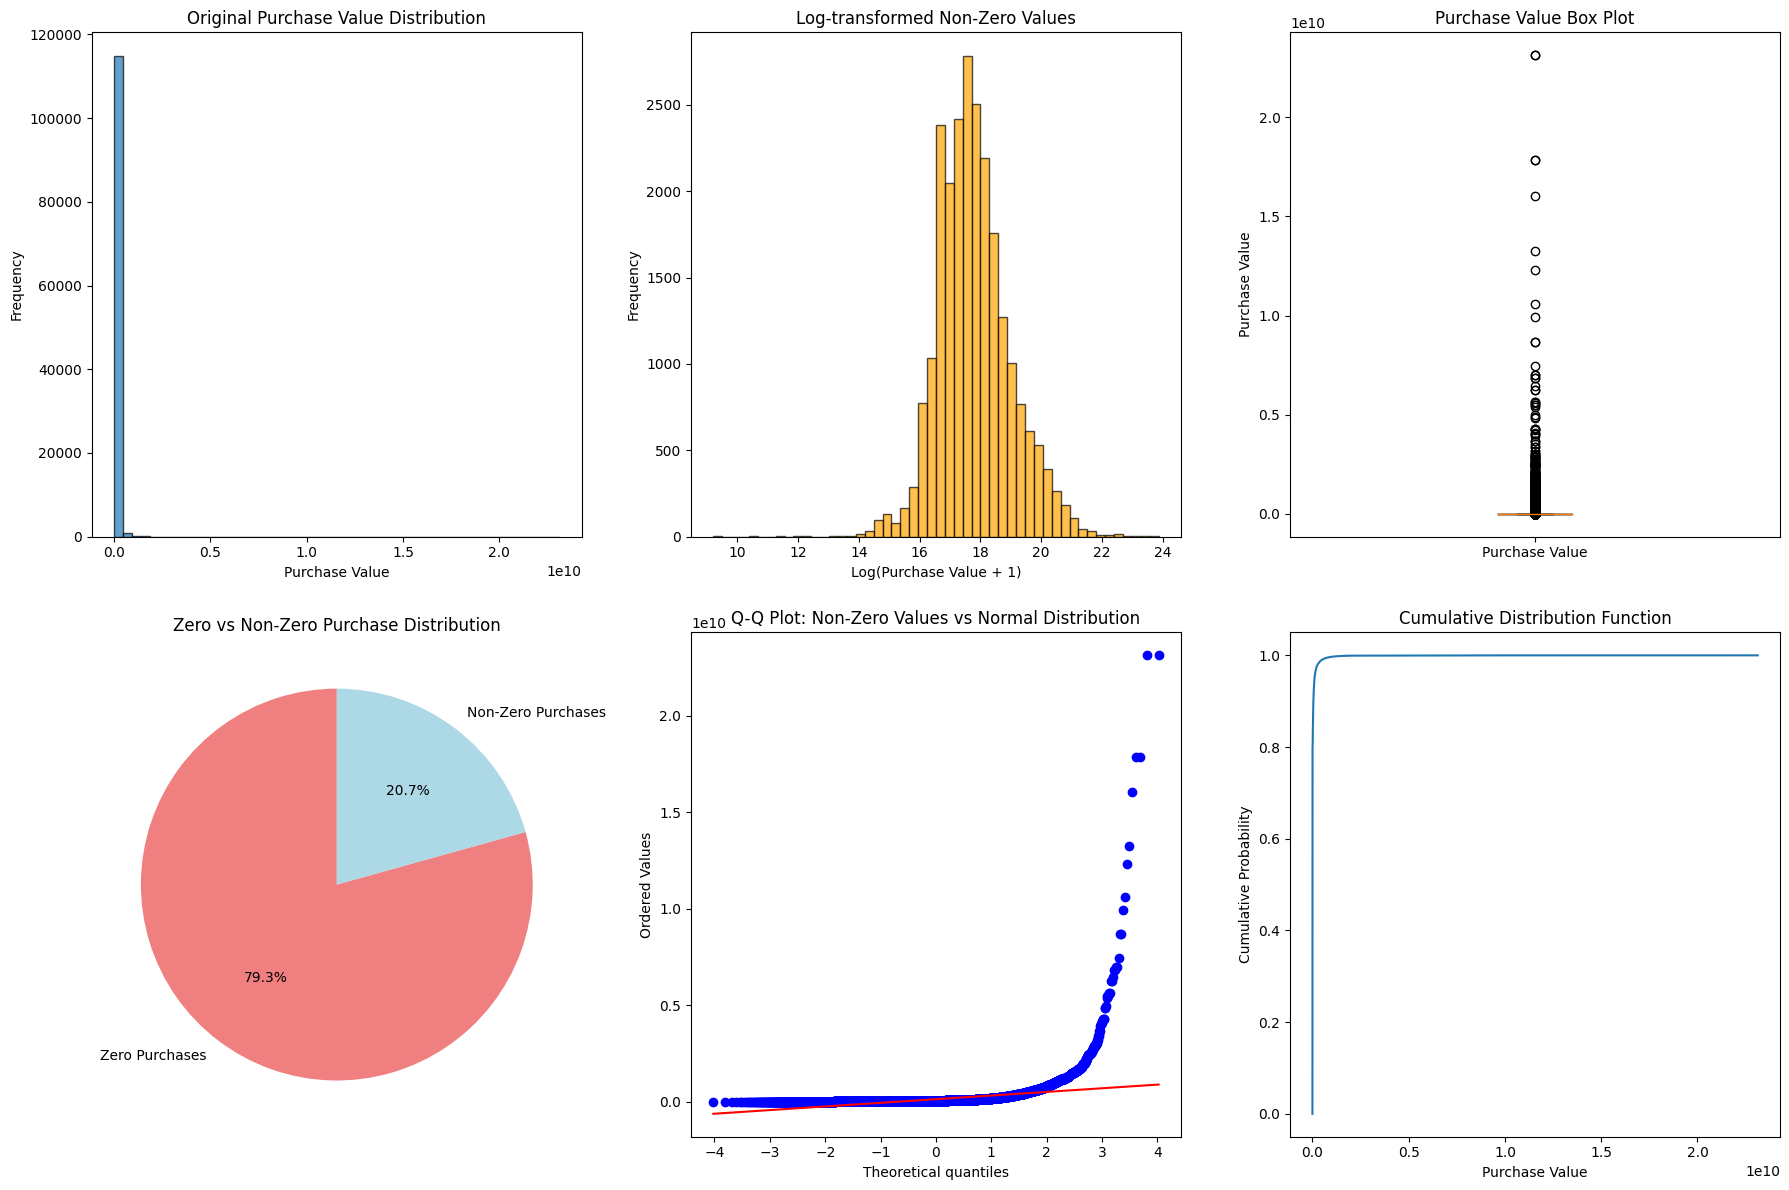

In [8]:
from scipy import stats
from scipy.stats import chi2_contingency

print("\n1. ZERO-INFLATION ANALYSIS")
print("-"*40)

zero_count = (df['purchaseValue'] == 0).sum()
non_zero_count = (df['purchaseValue'] > 0).sum()
total_count = len(df)

zero_percentage = (zero_count / total_count) * 100
non_zero_percentage = (non_zero_count / total_count) * 100

print(f"Total observations: {total_count:,}")
print(f"Zero purchases: {zero_count:,} ({zero_percentage:.2f}%)")
print(f"Non-zero purchases: {non_zero_count:,} ({non_zero_percentage:.2f}%)")

if zero_percentage > 60:
    print("High Zero-Inflation detected.")
elif zero_percentage > 30:
    print("Moderate Zero-Inflation detected.")
else:
    print("Low zero-inflation.")


print(f"\nNon-zero purchase value statistics:")
non_zero_values = df[df['purchaseValue'] > 0]['purchaseValue']
print(f"Mean: ${non_zero_values.mean():.2f}")
print(f"Median: ${non_zero_values.median():.2f}")
print(f"Std: ${non_zero_values.std():.2f}")
print(f"Min: ${non_zero_values.min():.2f}")
print(f"Max: ${non_zero_values.max():.2f}")

print("\n2. TARGET VARIABLE VISUALIZATION")
print("-"*35)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

axes[0,0].hist(df['purchaseValue'], bins=50, alpha=0.7, edgecolor='black')
axes[0,0].set_title('Original Purchase Value Distribution')
axes[0,0].set_xlabel('Purchase Value')
axes[0,0].set_ylabel('Frequency')

log_non_zero = np.log1p(non_zero_values)
axes[0,1].hist(log_non_zero, bins=50, alpha=0.7, edgecolor='black', color='orange')
axes[0,1].set_title('Log-transformed Non-Zero Values')
axes[0,1].set_xlabel('Log(Purchase Value + 1)')
axes[0,1].set_ylabel('Frequency')

axes[0,2].boxplot([df['purchaseValue']], labels=['Purchase Value'])
axes[0,2].set_title('Purchase Value Box Plot')
axes[0,2].set_ylabel('Purchase Value')

labels = ['Zero Purchases', 'Non-Zero Purchases']
sizes = [zero_count, non_zero_count]
colors = ['lightcoral', 'lightblue']
axes[1,0].pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%', startangle=90)
axes[1,0].set_title('Zero vs Non-Zero Purchase Distribution')

# QQ plot for non-zero values
stats.probplot(non_zero_values, dist="norm", plot=axes[1,1])
axes[1,1].set_title('Q-Q Plot: Non-Zero Values vs Normal Distribution')

# Cumulative distribution
sorted_values = np.sort(df['purchaseValue'])
cumulative_prob = np.arange(1, len(sorted_values) + 1) / len(sorted_values)
axes[1,2].plot(sorted_values, cumulative_prob)
axes[1,2].set_title('Cumulative Distribution Function')
axes[1,2].set_xlabel('Purchase Value')
axes[1,2].set_ylabel('Cumulative Probability')

plt.tight_layout()
plt.show()



UNIVARIATE ANALYSIS: UNDERSTANDING EACH FEATURE

1. NUMERICAL FEATURES ANALYSIS
-----------------------------------


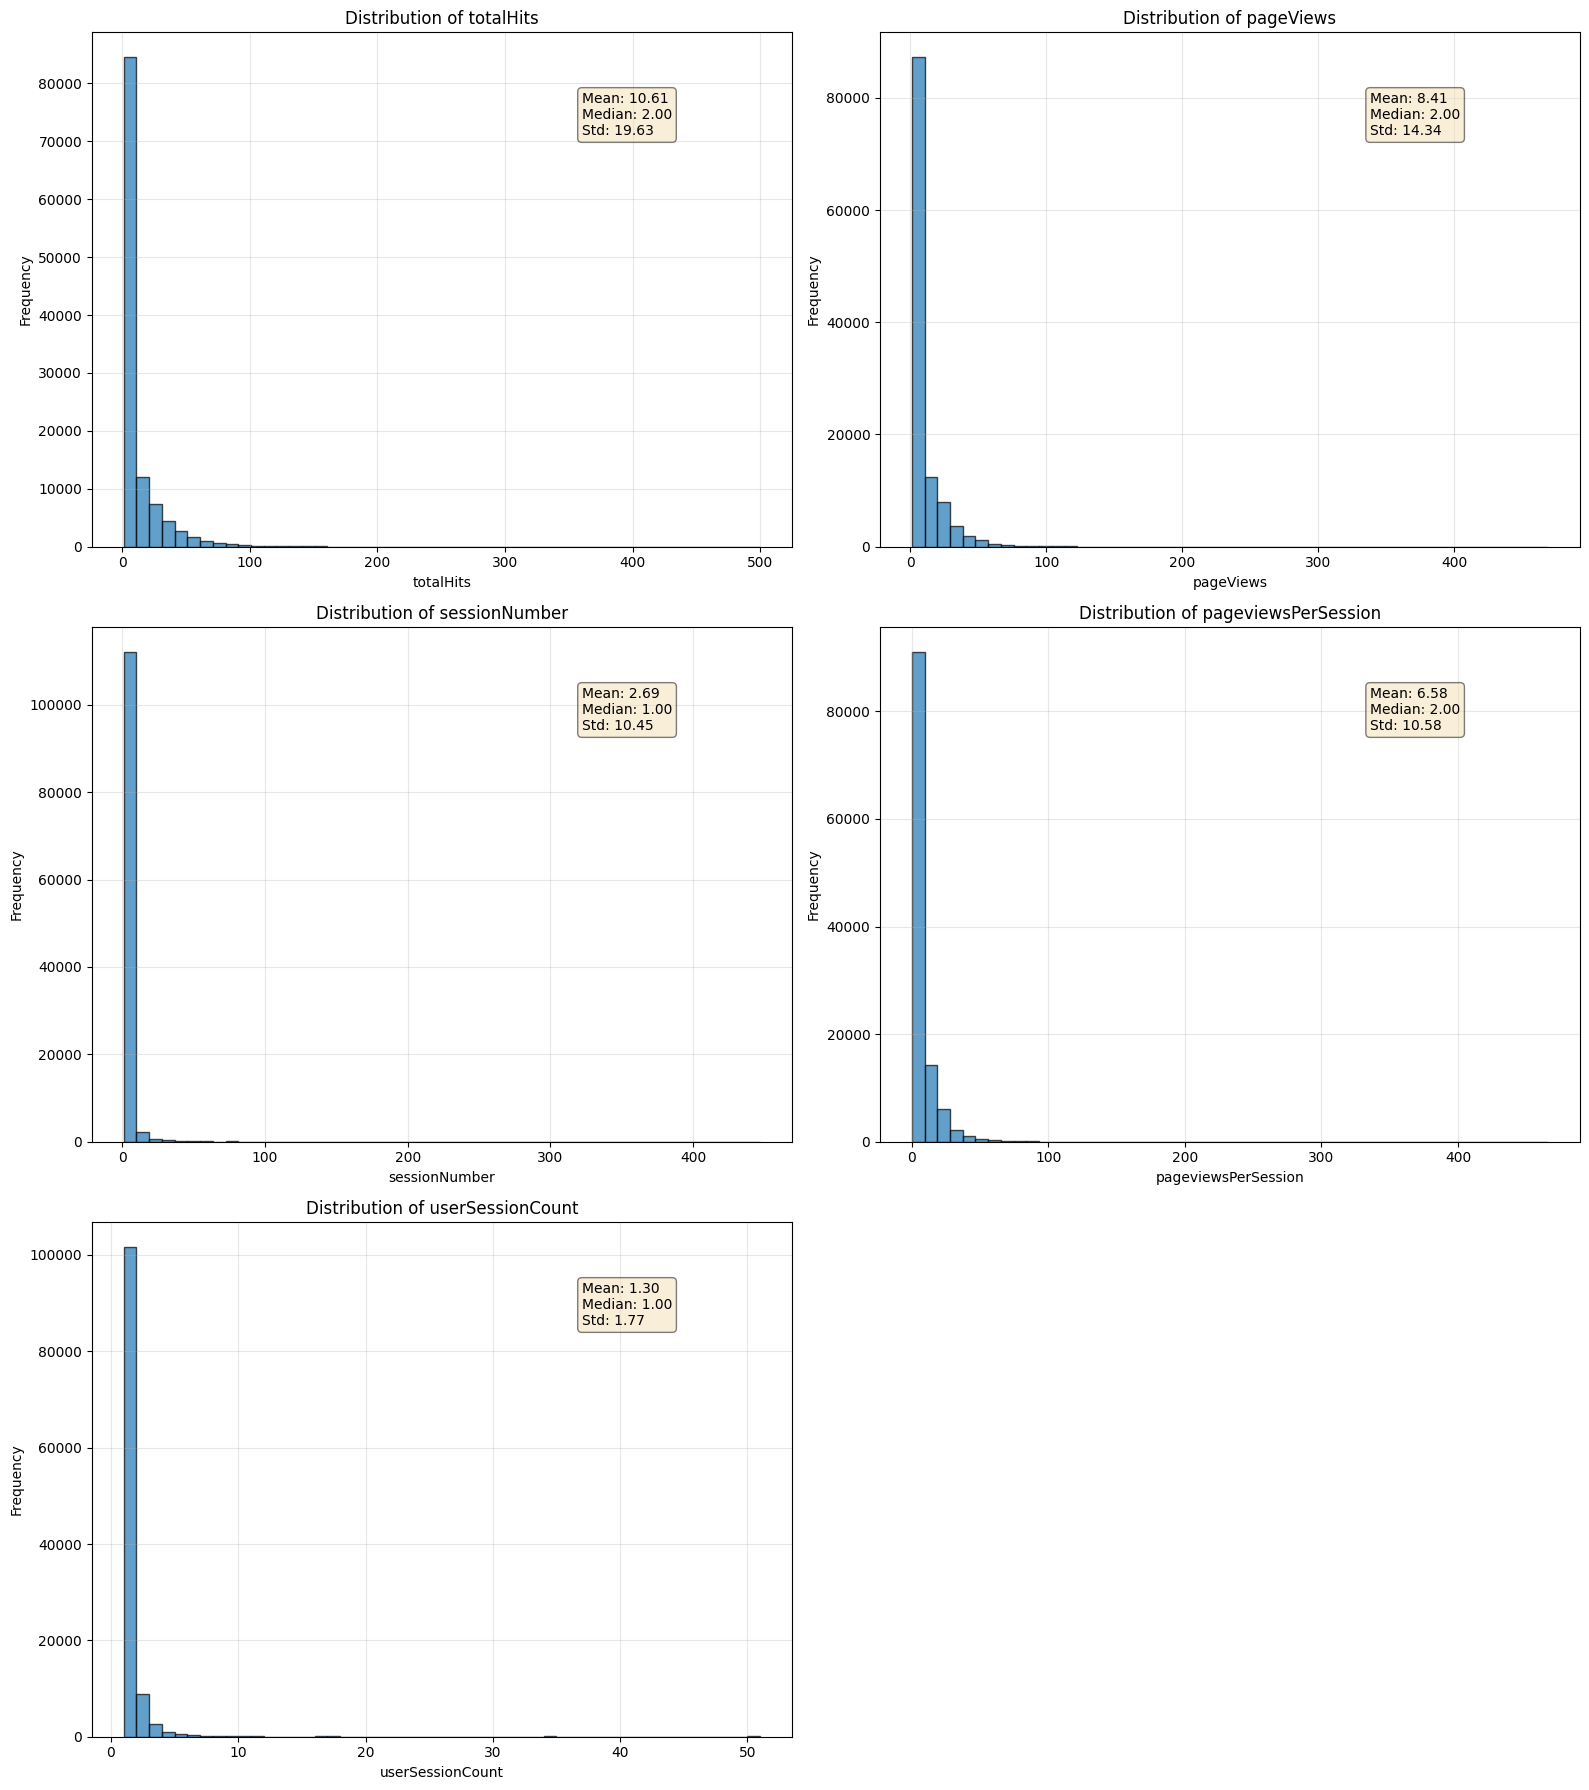


NUMERICAL FEATURES SUMMARY STATISTICS:
----------------------------------------
           totalHits      pageViews  sessionNumber  pageviewsPerSession  \
count  116023.000000  116015.000000  116023.000000        116015.000000   
mean       10.607371       8.412352       2.691311             6.576507   
std        19.629576      14.344937      10.451613            10.584536   
min         1.000000       1.000000       1.000000             0.250000   
25%         1.000000       1.000000       1.000000             0.999999   
50%         2.000000       2.000000       1.000000             1.999998   
75%        12.000000      10.000000       2.000000             7.999992   
max       500.000000     469.000000     447.000000           465.999534   

       userSessionCount  
count     116023.000000  
mean           1.301854  
std            1.769910  
min            1.000000  
25%            1.000000  
50%            1.000000  
75%            1.000000  
max           51.000000  


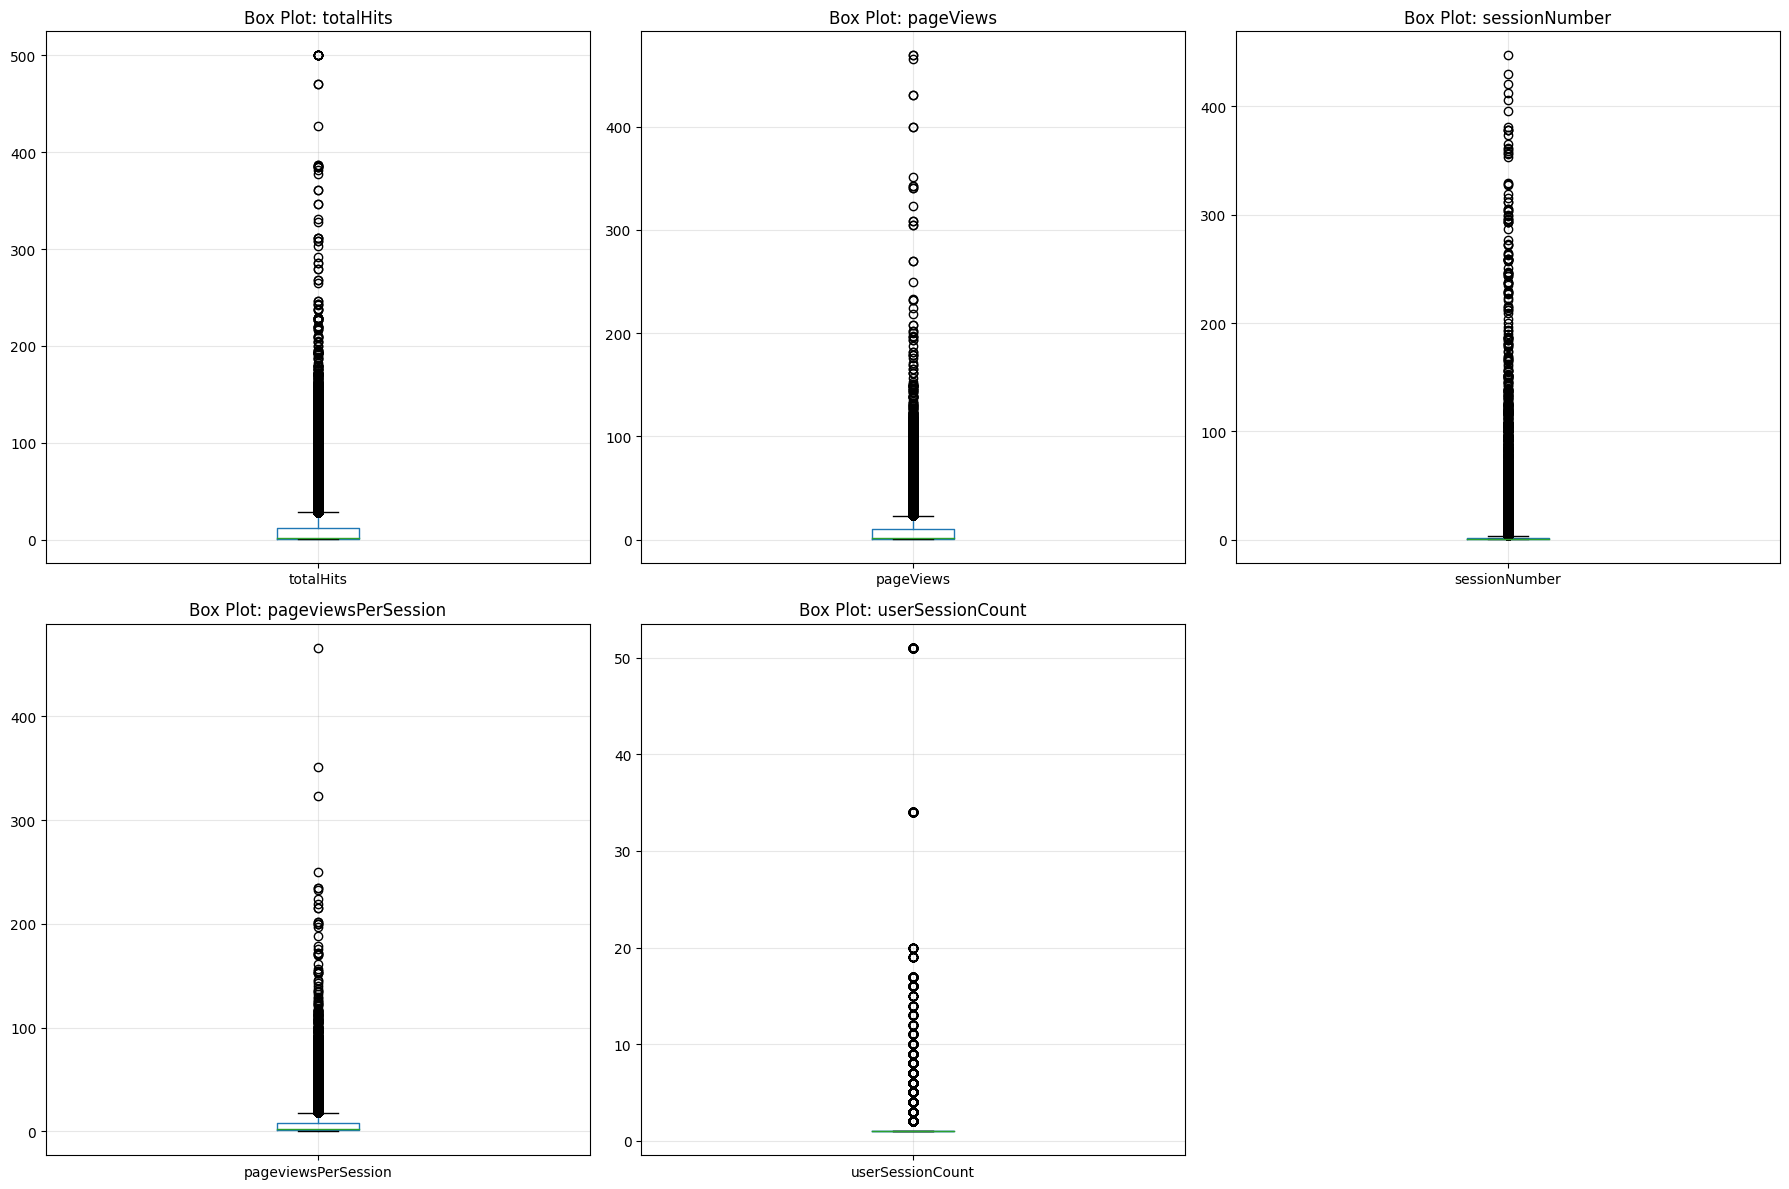


2. CATEGORICAL FEATURES ANALYSIS
---------------------------------


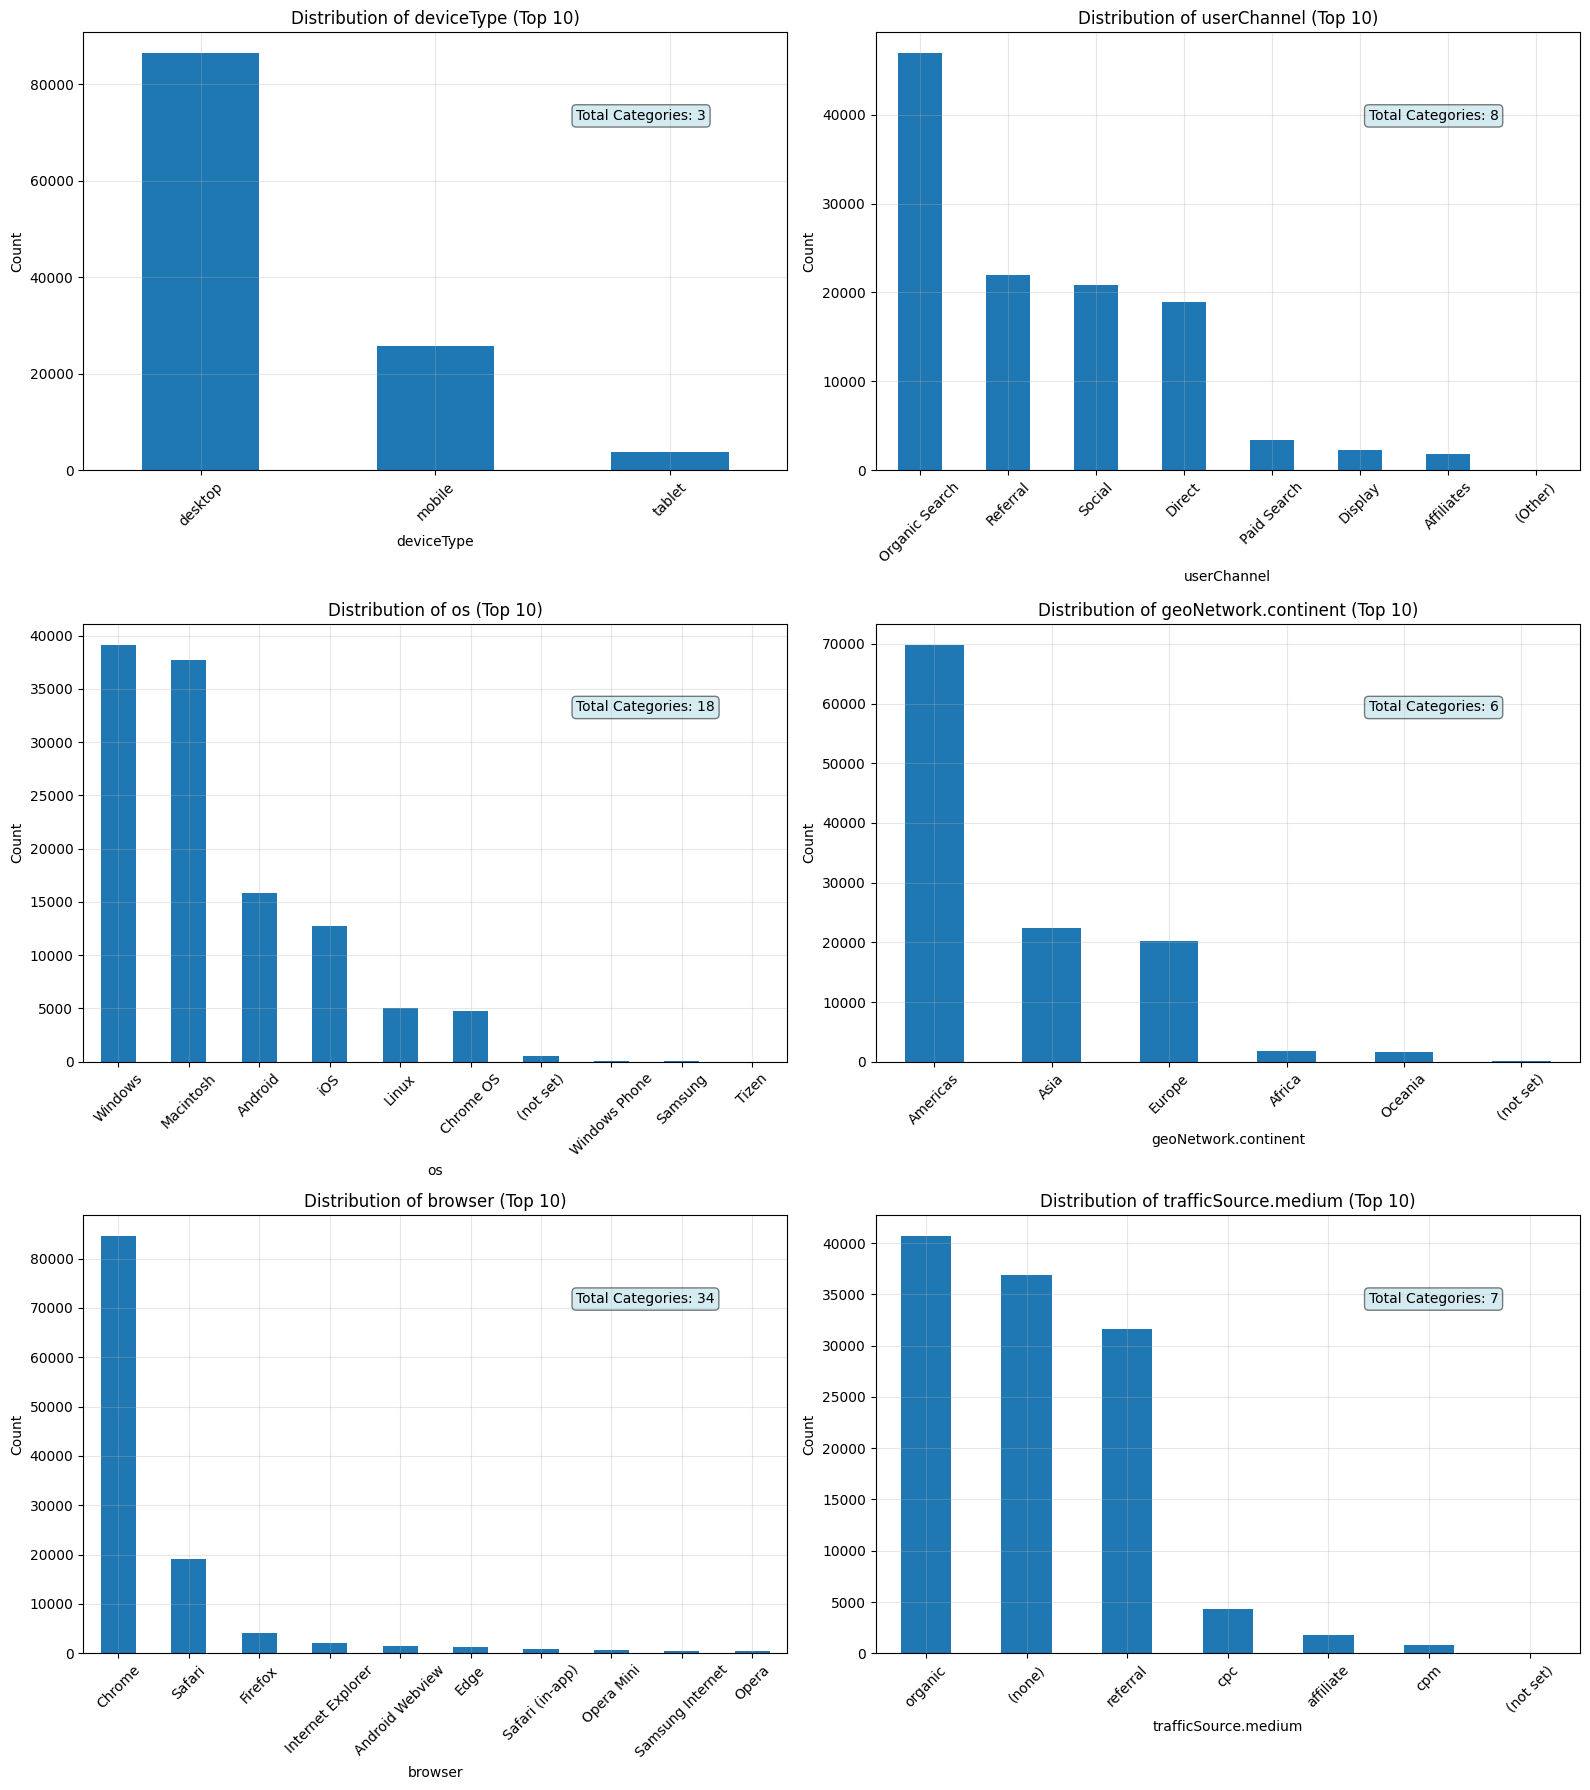


CATEGORICAL FEATURES DETAILED STATISTICS:
---------------------------------------------

deviceType:
  Unique values: 3
  Most common: desktop
  Top 5 categories:
    desktop: 86,480 (74.5%)
    mobile: 25,850 (22.3%)
    tablet: 3,693 (3.2%)

userChannel:
  Unique values: 8
  Most common: Organic Search
  Top 5 categories:
    Organic Search: 46,925 (40.4%)
    Referral: 21,932 (18.9%)
    Social: 20,786 (17.9%)
    Direct: 18,886 (16.3%)
    Paid Search: 3,406 (2.9%)

os:
  Unique values: 18
  Most common: Windows
  Top 5 categories:
    Windows: 39,135 (33.7%)
    Macintosh: 37,659 (32.5%)
    Android: 15,866 (13.7%)
    iOS: 12,762 (11.0%)
    Linux: 5,075 (4.4%)

geoNetwork.continent:
  Unique values: 6
  Most common: Americas
  Top 5 categories:
    Americas: 69,856 (60.2%)
    Asia: 22,384 (19.3%)
    Europe: 20,294 (17.5%)
    Africa: 1,747 (1.5%)
    Oceania: 1,606 (1.4%)

browser:
  Unique values: 34
  Most common: Chrome
  Top 5 categories:
    Chrome: 84,508 (72.8%)
    Sa

In [9]:
print("\n" + "="*80)
print("UNIVARIATE ANALYSIS: UNDERSTANDING EACH FEATURE")
print("="*80)

print("\n1. NUMERICAL FEATURES ANALYSIS")
print("-" * 35)

numerical_features = ['totalHits', 'pageViews', 'sessionNumber', 'pageviewsPerSession', 'userSessionCount']

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    if i < len(axes):
        axes[i].hist(df[feature], bins=50, edgecolor='black', alpha=0.7)
        axes[i].set_title(f'Distribution of {feature}')
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Frequency')
        axes[i].grid(True, alpha=0.3)
        
        mean_val = df[feature].mean()
        median_val = df[feature].median()
        std_val = df[feature].std()
        axes[i].text(0.7, 0.8, f'Mean: {mean_val:.2f}\nMedian: {median_val:.2f}\nStd: {std_val:.2f}', 
                    transform=axes[i].transAxes, bbox=dict(boxstyle="round", facecolor='wheat', alpha=0.5))

if len(numerical_features) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

print("\nNUMERICAL FEATURES SUMMARY STATISTICS:")
print("-" * 40)
print(df[numerical_features].describe())

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    if i < len(axes):
        df.boxplot(column=feature, ax=axes[i])
        axes[i].set_title(f'Box Plot: {feature}')
        axes[i].grid(True, alpha=0.3)

if len(numerical_features) < len(axes):
    fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

print("\n2. CATEGORICAL FEATURES ANALYSIS")
print("-" * 33)

categorical_features = ['deviceType', 'userChannel', 'os', 'geoNetwork.continent', 'browser', 'trafficSource.medium']

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

for i, feature in enumerate(categorical_features):
    if i < len(axes):
        value_counts = df[feature].value_counts().head(10)  # Top 10 categories
        value_counts.plot(kind='bar', ax=axes[i])
        axes[i].set_title(f'Distribution of {feature} (Top 10)')
        axes[i].set_xlabel(feature)
        axes[i].set_ylabel('Count')
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].grid(True, alpha=0.3)
        
        total_categories = df[feature].nunique()
        axes[i].text(0.7, 0.8, f'Total Categories: {total_categories}', 
                    transform=axes[i].transAxes, bbox=dict(boxstyle="round", facecolor='lightblue', alpha=0.5))

plt.tight_layout()
plt.show()

print("\nCATEGORICAL FEATURES DETAILED STATISTICS:")
print("-" * 45)
for feature in categorical_features:
    print(f"\n{feature}:")
    print(f"  Unique values: {df[feature].nunique()}")
    print(f"  Most common: {df[feature].mode().iloc[0] if len(df[feature].mode()) > 0 else 'N/A'}")
    print(f"  Top 5 categories:")
    top_5 = df[feature].value_counts().head(5)
    for cat, count in top_5.items():
        percentage = (count / len(df)) * 100
        print(f"    {cat}: {count:,} ({percentage:.1f}%)")


BIVARIATE ANALYSIS: CONNECTING FEATURES TO PURCHASE VALUE

1. USER BEHAVIOR & SESSION METRICS
-----------------------------------

ENGAGEMENT METRICS CORRELATION WITH PURCHASE VALUE:
----------------------------------------------------
totalHits: 0.2517
pageViews: 0.2485
sessionNumber: 0.2306
pageviewsPerSession: 0.2144

2. DEVICE & TECHNICAL ATTRIBUTES
---------------------------------


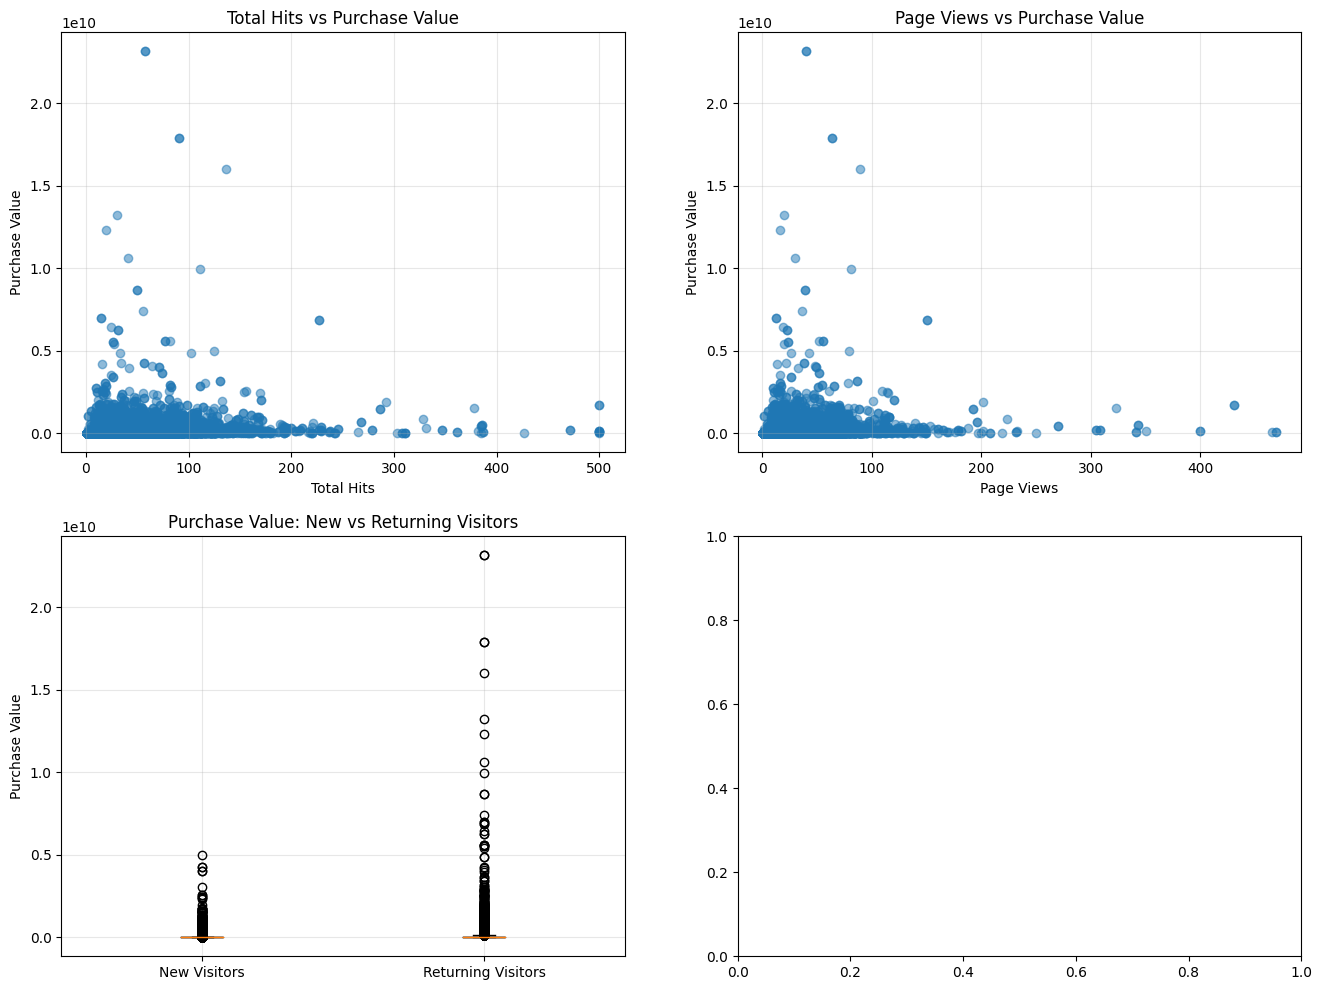

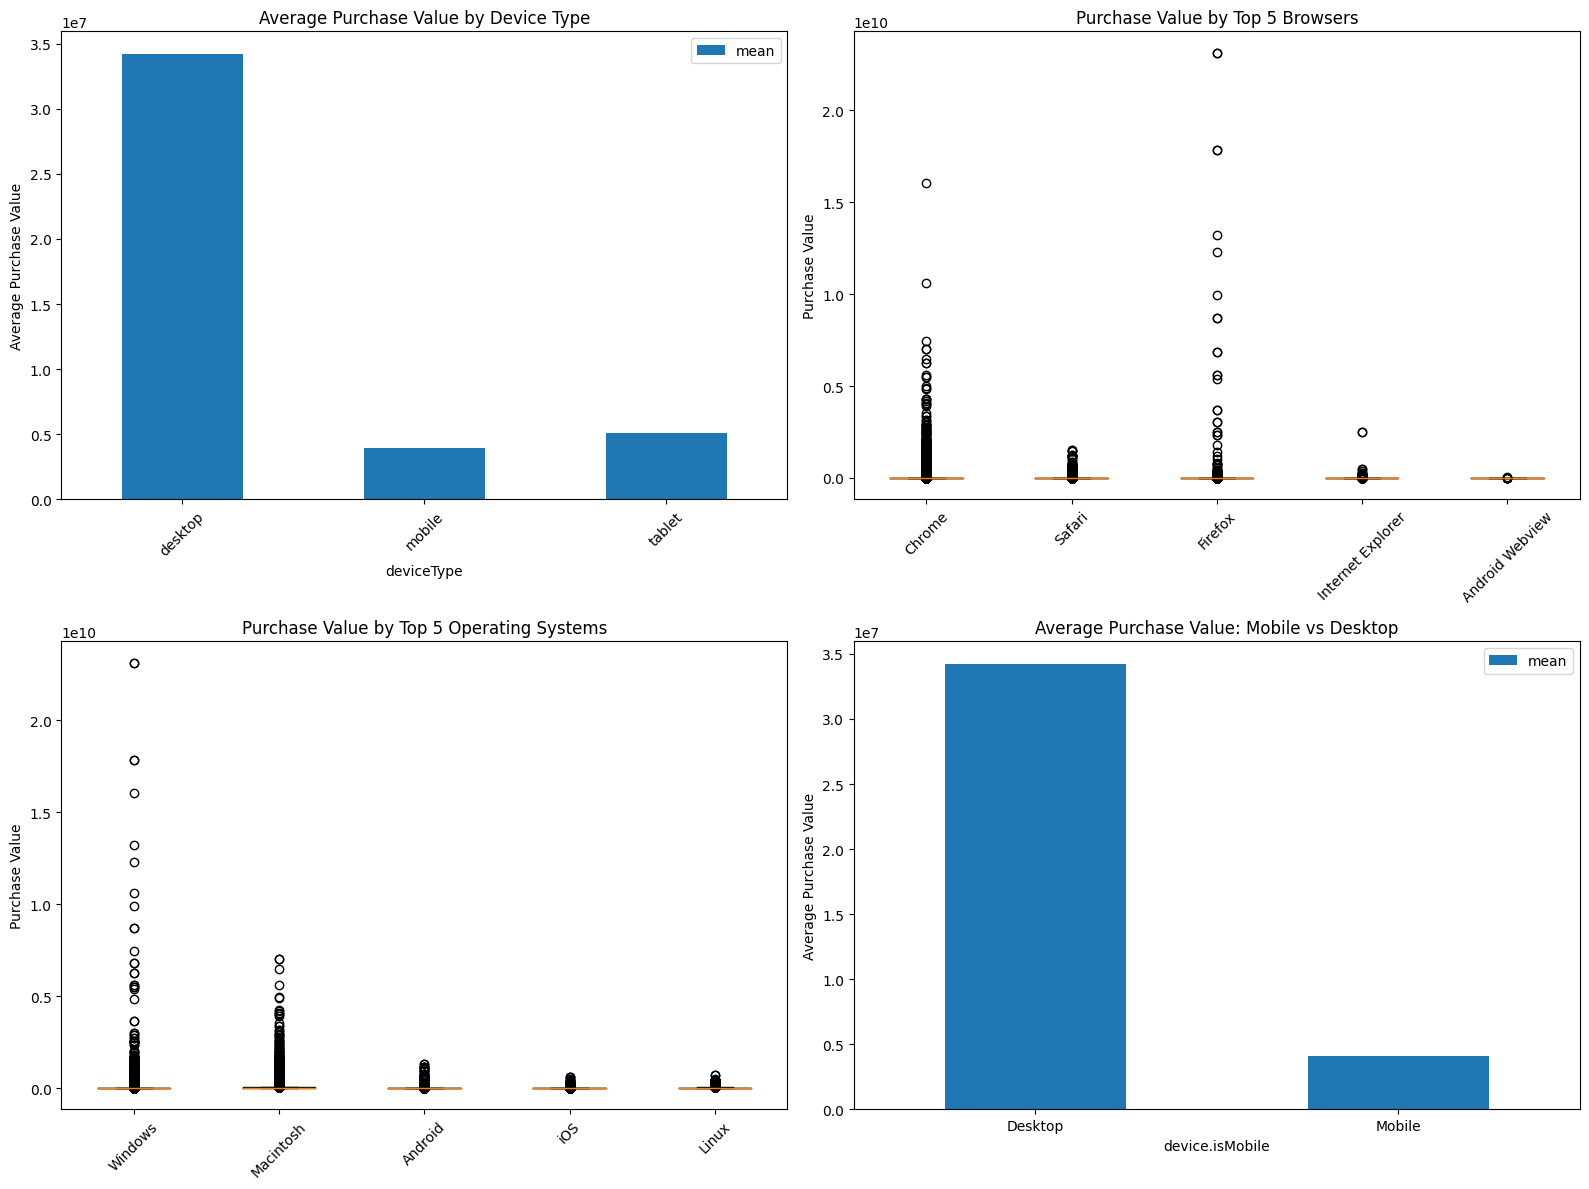


DEVICE PERFORMANCE SUMMARY:
----------------------------
By Device Type:
                   mean  median  count           sum
deviceType                                          
desktop     34247282.03     0.0  86480  2.961705e+12
mobile       3927222.05     0.0  25850  1.015187e+11
tablet       5091584.08     0.0   3693  1.880322e+10

By Mobile vs Desktop:
                mean  median  count           sum
Desktop  34241675.49     0.0  86494  2.961699e+12
Mobile    4074888.41     0.0  29529  1.203274e+11

3. TRAFFIC & MARKETING SOURCE ANALYSIS
--------------------------------------


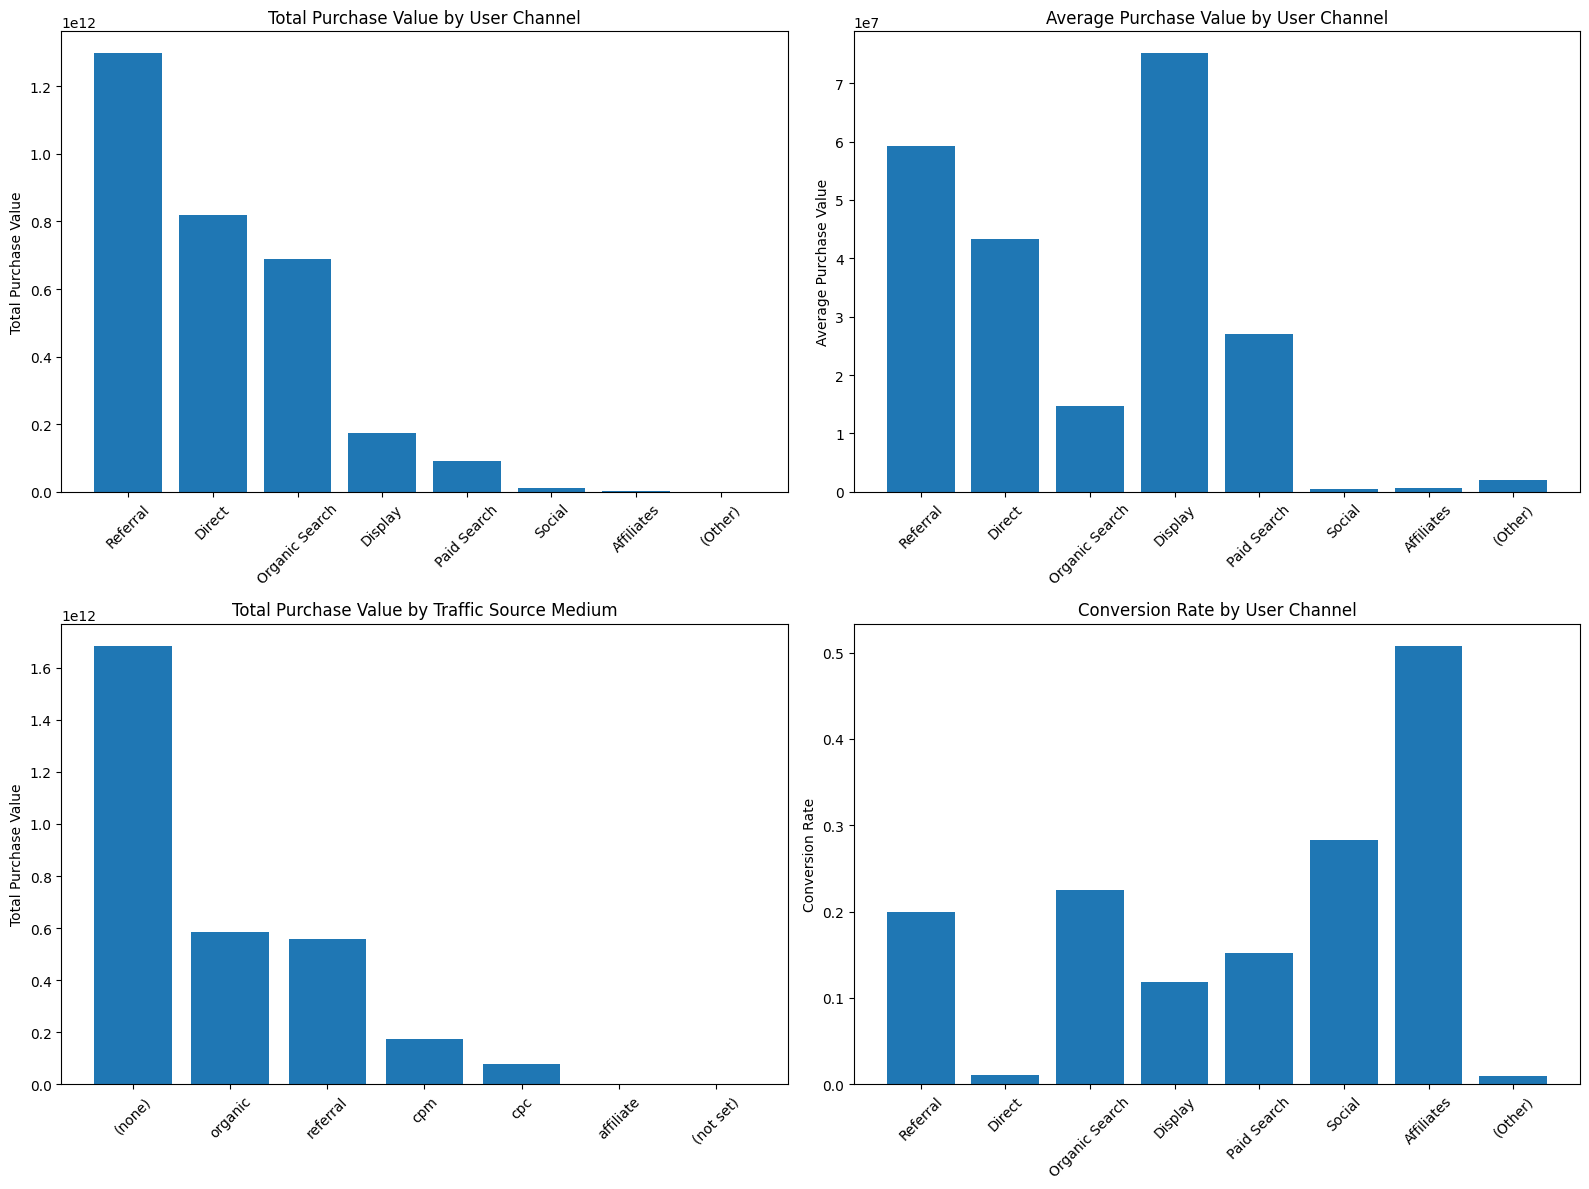


TRAFFIC SOURCE PERFORMANCE:
-----------------------------
By User Channel:
                        mean           sum  count  conversion_rate
userChannel                                                       
Referral        5.917188e+07  1.297758e+12  21932           0.5080
Direct          4.332910e+07  8.183135e+11  18886           0.2251
Organic Search  1.469966e+07  6.897814e+11  46925           0.1519
Display         7.514455e+07  1.729076e+11   2301           0.1186
Paid Search     2.711639e+07  9.235844e+10   3406           0.2827
Social          4.696204e+05  9.761530e+09  20786           0.0100
Affiliates      6.340180e+05  1.126650e+09   1777           0.0113
(Other)         1.998000e+06  1.998000e+07     10           0.2000

By Traffic Source Medium:
                              mean           sum  count  conversion_rate
trafficSource.medium                                                    
(none)                4.573531e+07  1.684752e+12  36837           0.3287
organic 

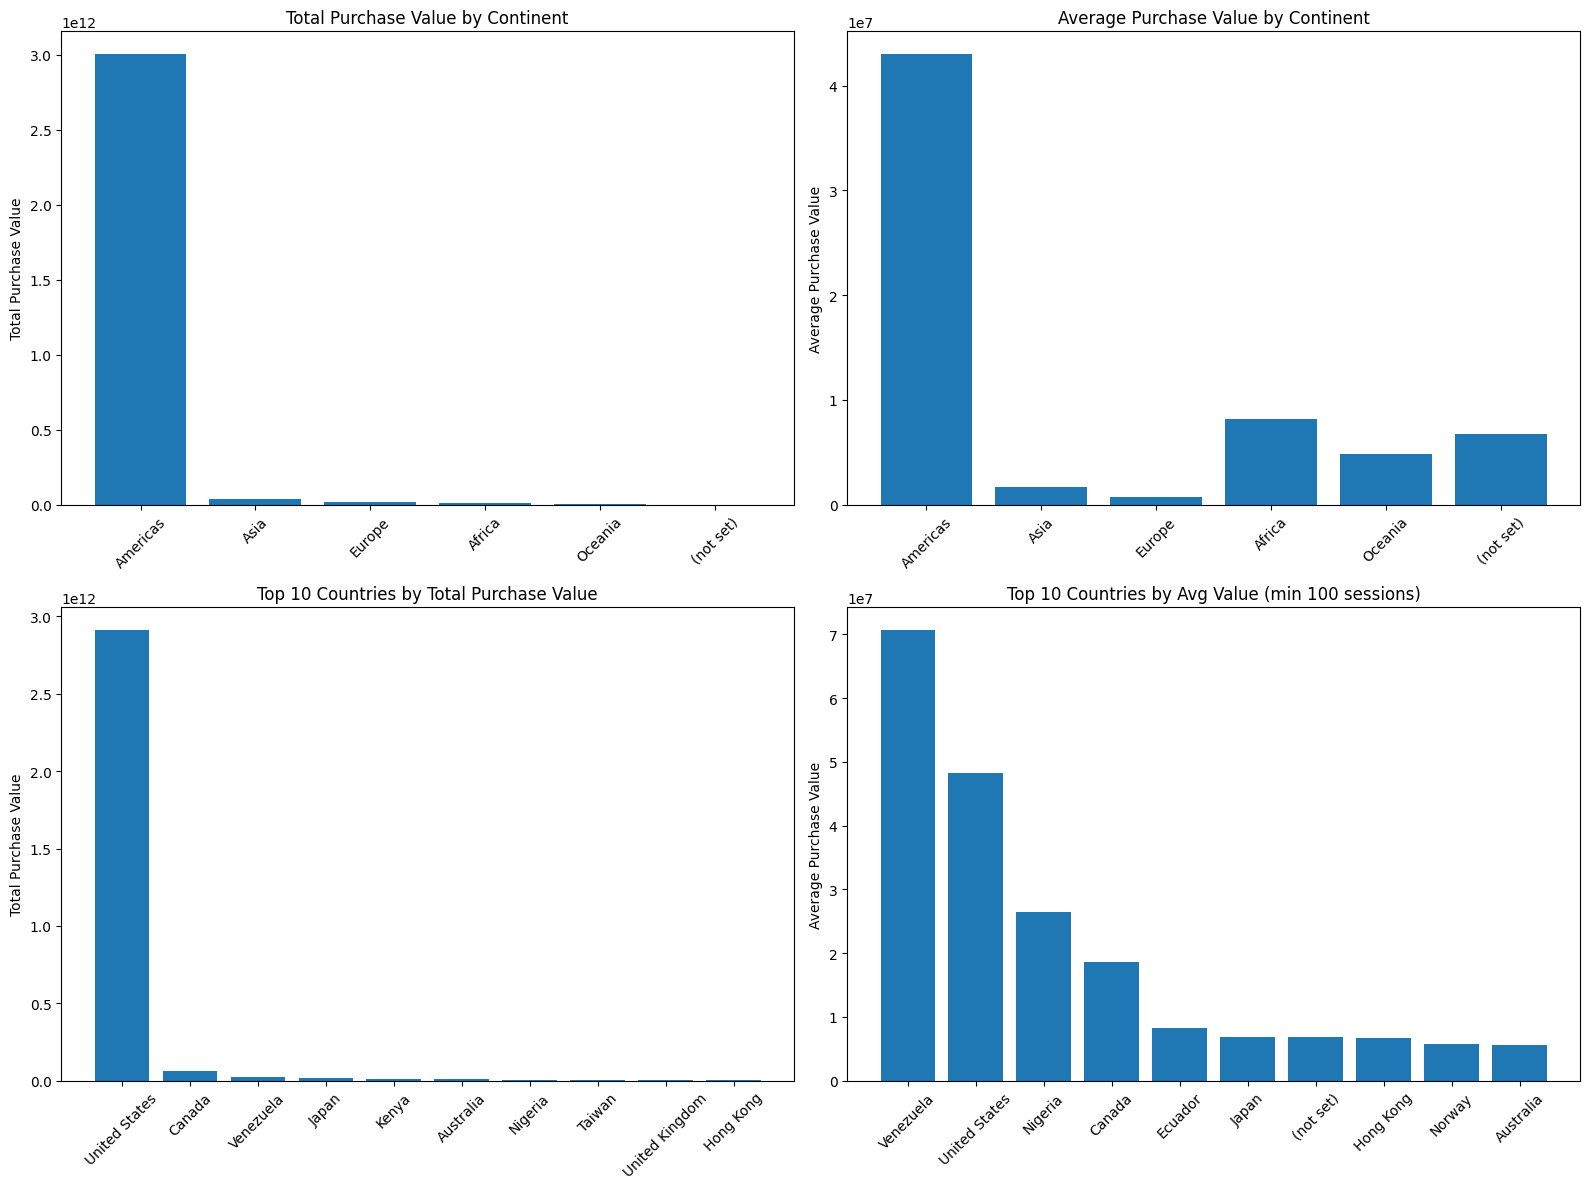


GEOGRAPHICAL PERFORMANCE:
-------------------------
By Continent:
                              mean           sum  count  conversion_rate
geoNetwork.continent                                                    
Americas              4.304335e+07  3.006836e+12  69856           0.3366
Asia                  1.645135e+06  3.682471e+10  22384           0.0115
Europe                7.576836e+05  1.537643e+10  20294           0.0081
Africa                8.218907e+06  1.435843e+10   1747           0.0080
Oceania               4.801270e+06  7.710840e+09   1606           0.0187
(not set)             6.768382e+06  9.205000e+08    136           0.0662

Top 10 Countries by Total Value:
    locationCountry          mean           sum  count
185   United States  4.826599e+07  2.913770e+12  60369
31           Canada  1.866913e+07  6.022662e+10   3226
188       Venezuela  7.071821e+07  2.050828e+10    290
86            Japan  6.797011e+06  1.380473e+10   2031
90            Kenya  1.302603e+08  8.857

In [10]:
print("\n" + "="*80)
print("BIVARIATE ANALYSIS: CONNECTING FEATURES TO PURCHASE VALUE")
print("="*80)

print("\n1. USER BEHAVIOR & SESSION METRICS")
print("-" * 35)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0,0].scatter(df['totalHits'], df['purchaseValue'], alpha=0.5)
axes[0,0].set_xlabel('Total Hits')
axes[0,0].set_ylabel('Purchase Value')
axes[0,0].set_title('Total Hits vs Purchase Value')
axes[0,0].grid(True, alpha=0.3)

axes[0,1].scatter(df['pageViews'], df['purchaseValue'], alpha=0.5)
axes[0,1].set_xlabel('Page Views')
axes[0,1].set_ylabel('Purchase Value')
axes[0,1].set_title('Page Views vs Purchase Value')
axes[0,1].grid(True, alpha=0.3)

new_visitors = df[df['new_visits'] == 1]['purchaseValue']
returning_visitors = df[df['new_visits'].isna()]['purchaseValue']

axes[1,0].boxplot([new_visitors, returning_visitors], labels=['New Visitors', 'Returning Visitors'])
axes[1,0].set_ylabel('Purchase Value')
axes[1,0].set_title('Purchase Value: New vs Returning Visitors')
axes[1,0].grid(True, alpha=0.3)

print("\nENGAGEMENT METRICS CORRELATION WITH PURCHASE VALUE:")
print("-" * 52)
engagement_metrics = ['totalHits', 'pageViews', 'sessionNumber', 'pageviewsPerSession']
for metric in engagement_metrics:
    correlation = df[metric].corr(df['purchaseValue'])
    print(f"{metric}: {correlation:.4f}")

print("\n2. DEVICE & TECHNICAL ATTRIBUTES")
print("-" * 33)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

device_stats = df.groupby('deviceType')['purchaseValue'].agg(['mean', 'count']).reset_index()
device_stats.plot(x='deviceType', y='mean', kind='bar', ax=axes[0,0])
axes[0,0].set_title('Average Purchase Value by Device Type')
axes[0,0].set_ylabel('Average Purchase Value')
axes[0,0].tick_params(axis='x', rotation=45)

top_browsers = df['browser'].value_counts().head(5).index
browser_data = [df[df['browser'] == browser]['purchaseValue'] for browser in top_browsers]
axes[0,1].boxplot(browser_data, labels=top_browsers)
axes[0,1].set_title('Purchase Value by Top 5 Browsers')
axes[0,1].set_ylabel('Purchase Value')
axes[0,1].tick_params(axis='x', rotation=45)

top_os = df['os'].value_counts().head(5).index
os_data = [df[df['os'] == os]['purchaseValue'] for os in top_os]
axes[1,0].boxplot(os_data, labels=top_os)
axes[1,0].set_title('Purchase Value by Top 5 Operating Systems')
axes[1,0].set_ylabel('Purchase Value')
axes[1,0].tick_params(axis='x', rotation=45)

mobile_desktop_stats = df.groupby('device.isMobile')['purchaseValue'].agg(['mean', 'median', 'count'])
mobile_desktop_stats.plot(y='mean', kind='bar', ax=axes[1,1])
axes[1,1].set_title('Average Purchase Value: Mobile vs Desktop')
axes[1,1].set_ylabel('Average Purchase Value')
axes[1,1].set_xticklabels(['Desktop', 'Mobile'], rotation=0)

plt.tight_layout()
plt.show()

print("\nDEVICE PERFORMANCE SUMMARY:")
print("-" * 28)
print("By Device Type:")
device_summary = df.groupby('deviceType')['purchaseValue'].agg(['mean', 'median', 'count', 'sum'])
print(device_summary.round(2))

print("\nBy Mobile vs Desktop:")
mobile_summary = df.groupby('device.isMobile')['purchaseValue'].agg(['mean', 'median', 'count', 'sum'])
mobile_summary.index = ['Desktop', 'Mobile']
print(mobile_summary.round(2))

print("\n3. TRAFFIC & MARKETING SOURCE ANALYSIS")
print("-" * 38)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

channel_stats = df.groupby('userChannel')['purchaseValue'].agg(['mean', 'sum', 'count']).reset_index()
channel_stats = channel_stats.sort_values('sum', ascending=False)

axes[0,0].bar(channel_stats['userChannel'], channel_stats['sum'])
axes[0,0].set_title('Total Purchase Value by User Channel')
axes[0,0].set_ylabel('Total Purchase Value')
axes[0,0].tick_params(axis='x', rotation=45)

axes[0,1].bar(channel_stats['userChannel'], channel_stats['mean'])
axes[0,1].set_title('Average Purchase Value by User Channel')
axes[0,1].set_ylabel('Average Purchase Value')
axes[0,1].tick_params(axis='x', rotation=45)

medium_stats = df.groupby('trafficSource.medium')['purchaseValue'].agg(['mean', 'sum', 'count']).reset_index()
medium_stats = medium_stats.sort_values('sum', ascending=False)

axes[1,0].bar(medium_stats['trafficSource.medium'], medium_stats['sum'])
axes[1,0].set_title('Total Purchase Value by Traffic Source Medium')
axes[1,0].set_ylabel('Total Purchase Value')
axes[1,0].tick_params(axis='x', rotation=45)

channel_stats['conversion_rate'] = (df.groupby('userChannel')['purchaseValue'].apply(lambda x: (x > 0).mean()).values)
axes[1,1].bar(channel_stats['userChannel'], channel_stats['conversion_rate'])
axes[1,1].set_title('Conversion Rate by User Channel')
axes[1,1].set_ylabel('Conversion Rate')
axes[1,1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print("\nTRAFFIC SOURCE PERFORMANCE:")
print("-" * 29)
print("By User Channel:")
channel_performance = df.groupby('userChannel')['purchaseValue'].agg(['mean', 'sum', 'count'])
channel_performance['conversion_rate'] = df.groupby('userChannel')['purchaseValue'].apply(lambda x: (x > 0).mean())
print(channel_performance.sort_values('sum', ascending=False).round(4))

print("\nBy Traffic Source Medium:")
medium_performance = df.groupby('trafficSource.medium')['purchaseValue'].agg(['mean', 'sum', 'count'])
medium_performance['conversion_rate'] = df.groupby('trafficSource.medium')['purchaseValue'].apply(lambda x: (x > 0).mean())
print(medium_performance.sort_values('sum', ascending=False).round(4))

print("\n4. GEOGRAPHICAL ANALYSIS")
print("-" * 25)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

continent_stats = df.groupby('geoNetwork.continent')['purchaseValue'].agg(['mean', 'sum', 'count']).reset_index()
continent_stats = continent_stats.sort_values('sum', ascending=False)

axes[0,0].bar(continent_stats['geoNetwork.continent'], continent_stats['sum'])
axes[0,0].set_title('Total Purchase Value by Continent')
axes[0,0].set_ylabel('Total Purchase Value')
axes[0,0].tick_params(axis='x', rotation=45)

axes[0,1].bar(continent_stats['geoNetwork.continent'], continent_stats['mean'])
axes[0,1].set_title('Average Purchase Value by Continent')
axes[0,1].set_ylabel('Average Purchase Value')
axes[0,1].tick_params(axis='x', rotation=45)

country_stats = df.groupby('locationCountry')['purchaseValue'].agg(['mean', 'sum', 'count']).reset_index()
top_countries = country_stats.sort_values('sum', ascending=False).head(10)

axes[1,0].bar(range(len(top_countries)), top_countries['sum'])
axes[1,0].set_title('Top 10 Countries by Total Purchase Value')
axes[1,0].set_ylabel('Total Purchase Value')
axes[1,0].set_xticks(range(len(top_countries)))
axes[1,0].set_xticklabels(top_countries['locationCountry'], rotation=45)

high_volume_countries = country_stats[country_stats['count'] >= 100].sort_values('mean', ascending=False).head(10)
axes[1,1].bar(range(len(high_volume_countries)), high_volume_countries['mean'])
axes[1,1].set_title('Top 10 Countries by Avg Value (min 100 sessions)')
axes[1,1].set_ylabel('Average Purchase Value')
axes[1,1].set_xticks(range(len(high_volume_countries)))
axes[1,1].set_xticklabels(high_volume_countries['locationCountry'], rotation=45)

plt.tight_layout()
plt.show()

print("\nGEOGRAPHICAL PERFORMANCE:")
print("-" * 25)
print("By Continent:")
geo_performance = df.groupby('geoNetwork.continent')['purchaseValue'].agg(['mean', 'sum', 'count'])
geo_performance['conversion_rate'] = df.groupby('geoNetwork.continent')['purchaseValue'].apply(lambda x: (x > 0).mean())
print(geo_performance.sort_values('sum', ascending=False).round(4))

print("\nTop 10 Countries by Total Value:")
print(top_countries[['locationCountry', 'mean', 'sum', 'count']].round(2))

print("\n PURCHASE BEHAVIOR INSIGHTS:")
print("-" * 32)

total_sessions = len(df)
purchasing_sessions = len(df[df['purchaseValue'] > 0])
overall_conversion = purchasing_sessions / total_sessions

print(f"Overall conversion rate: {overall_conversion:.3f} ({purchasing_sessions:,} out of {total_sessions:,})")

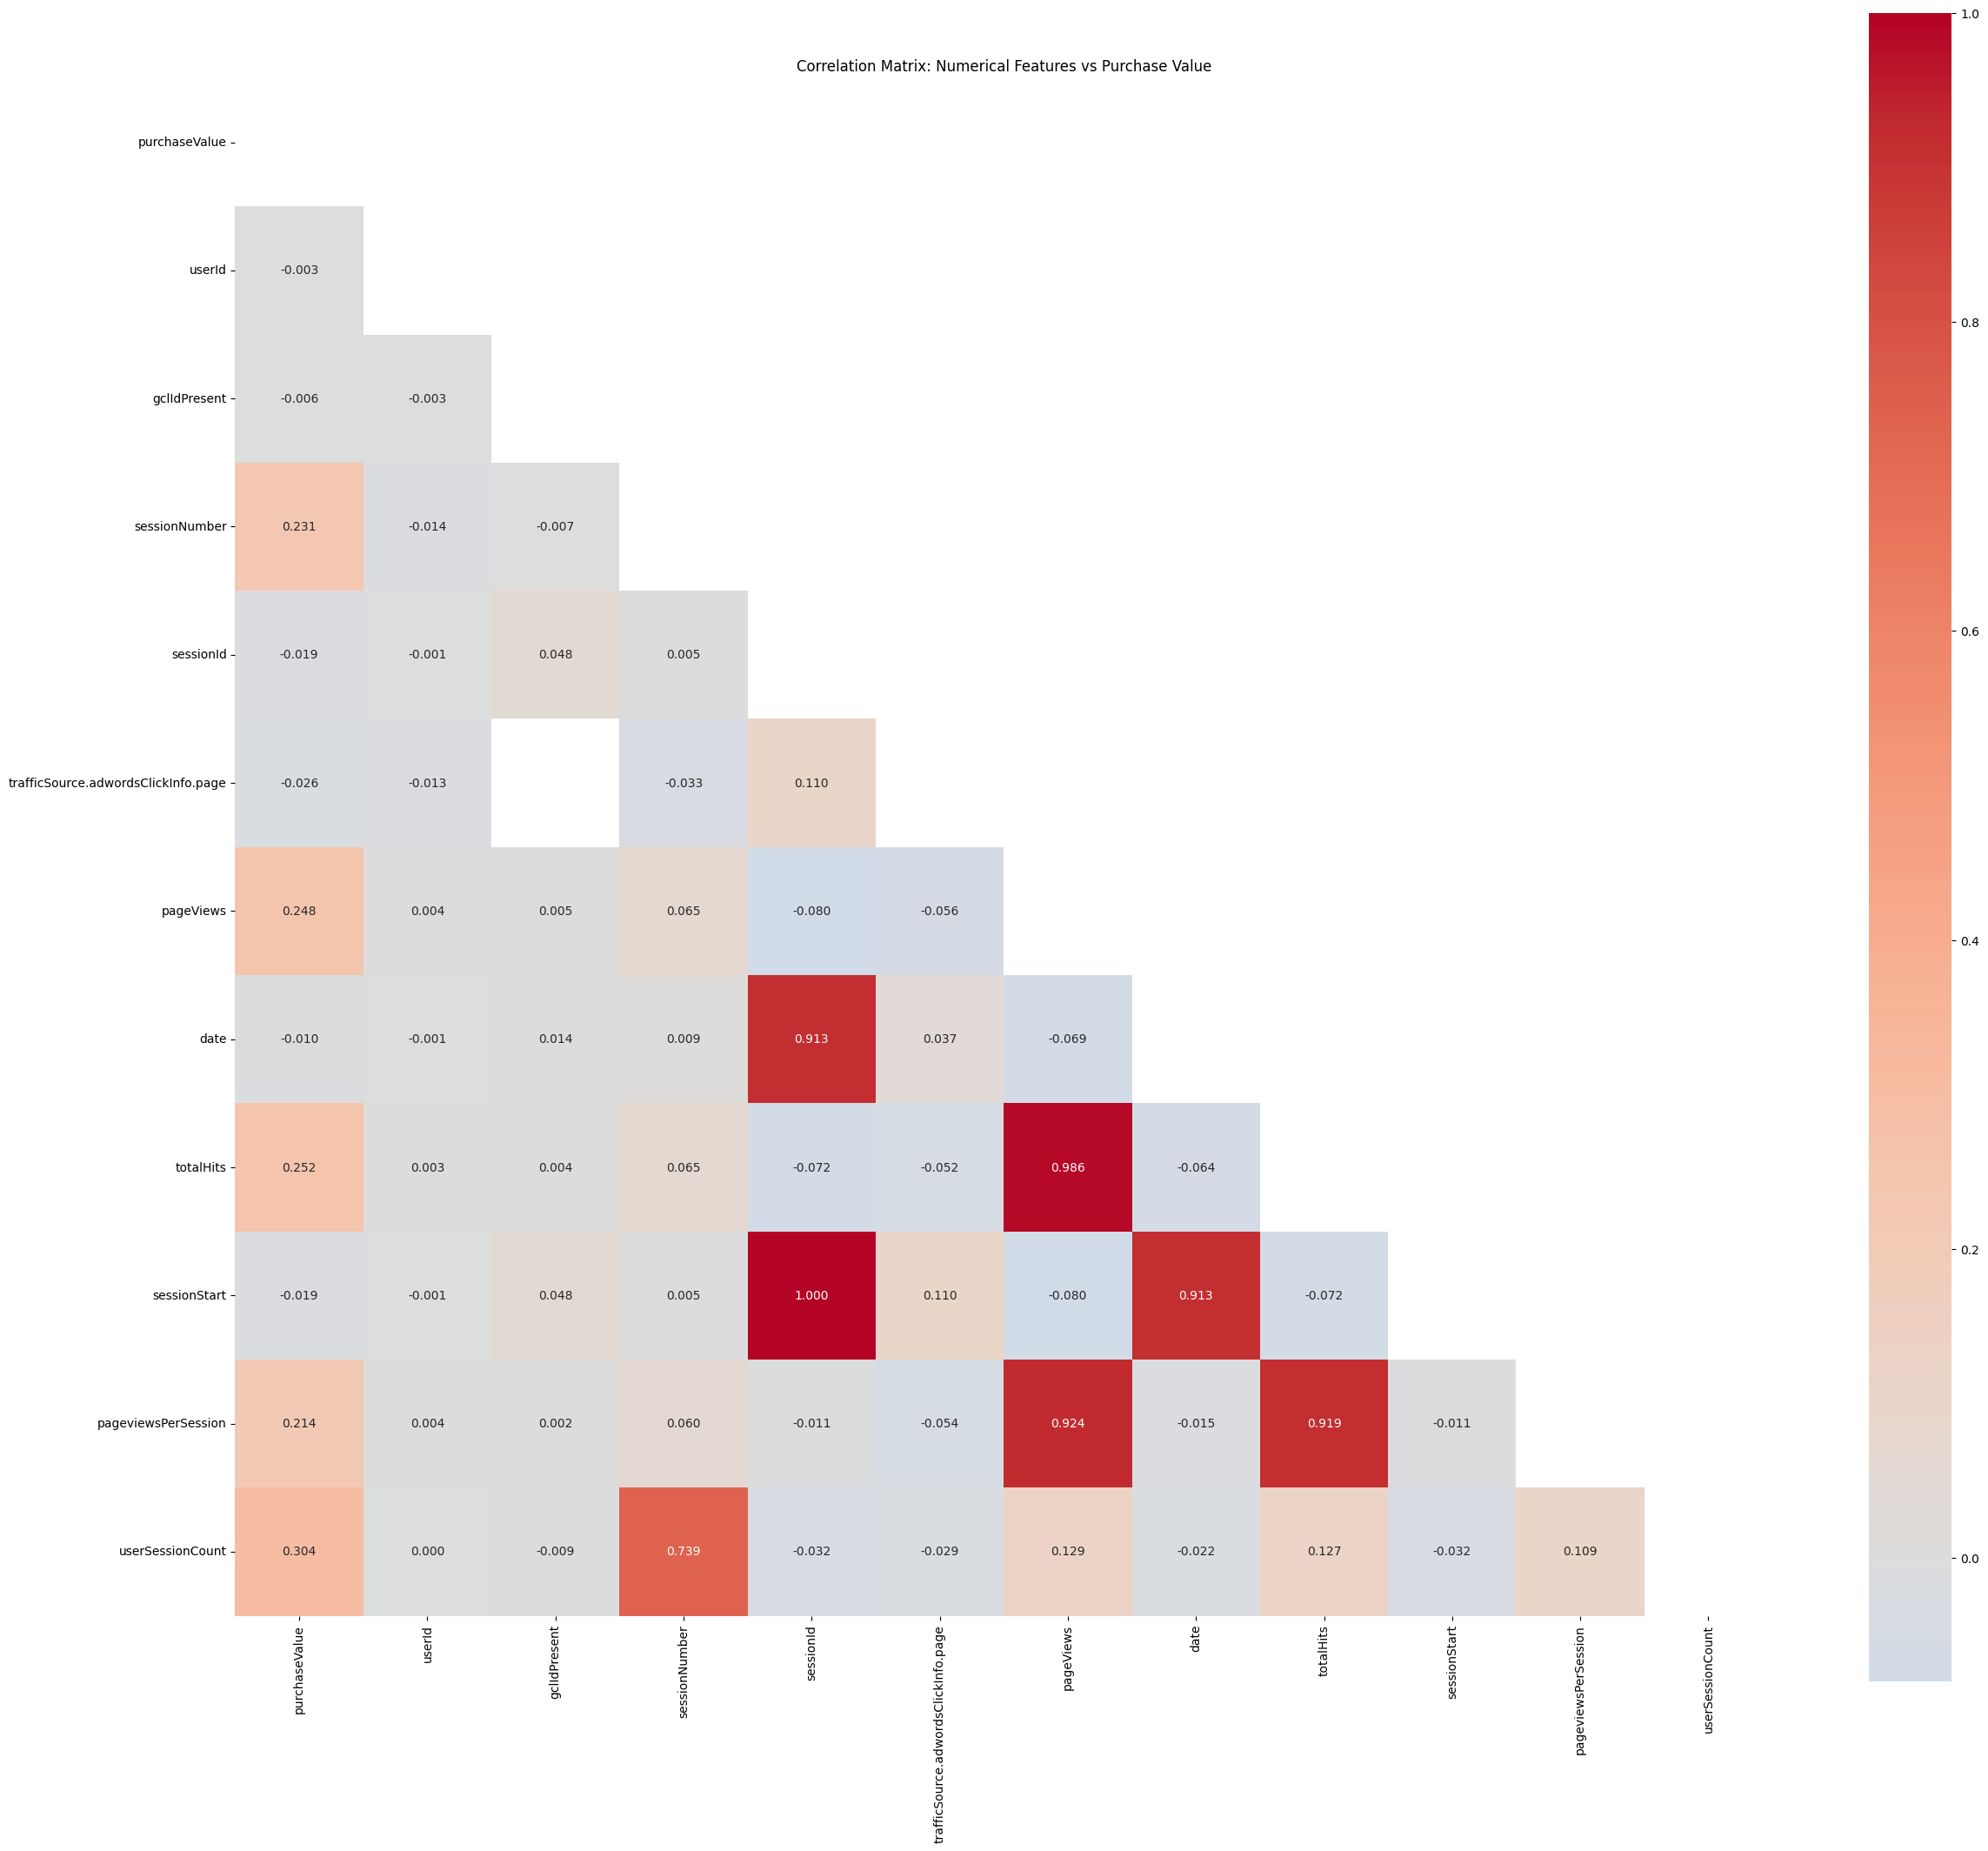

In [11]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()

for i in ['totals.visits', 'totals.bounces', 'locationZone', 'new_visits']:
    numerical_cols.remove(i)

corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(25, 25))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, cmap='coolwarm', center=0,
            square=True, fmt='.3f', cbar_kws={"shrink": .8})
plt.title('Correlation Matrix: Numerical Features vs Purchase Value')
plt.tight_layout()
plt.show()

# Preprocessing

In [12]:
def drop_columns(df: pd.DataFrame):
    columns_to_drop = []
    for column in df.columns:
        if df[column].dtype == 'object' and len(df[column].unique()) <= 1:  # Only check object/string columns
            if (df[column].unique() == ['not available in demo dataset']):
                columns_to_drop.append(column)

    print("Columns with 'not available in demo dataset' values:")
    print(columns_to_drop)

    df.drop(columns=columns_to_drop, inplace=True)

    missing_threshold = 0.8
    columns_to_drop = df.columns[df.isnull().mean() > missing_threshold]
    df.drop(columns=columns_to_drop, inplace=True)
    df.drop(columns=['totals.visits', 'totals.bounces', 'locationZone'], inplace=True)

    return df

df = drop_columns(df)

Columns with 'not available in demo dataset' values:
['device.screenResolution', 'device.mobileDeviceBranding', 'device.mobileInputSelector', 'device.mobileDeviceMarketingName', 'device.operatingSystemVersion', 'device.flashVersion', 'geoNetwork.networkLocation', 'browserMajor', 'device.browserSize', 'device.mobileDeviceModel', 'device.language', 'device.browserVersion', 'device.screenColors']


In [13]:
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 236


In [14]:
# PREPROCESSING PIPELINE

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from category_encoders import TargetEncoder

print("\n1. TRAIN-TEST SPLIT")
print("-"*20)

X = df.drop('purchaseValue', axis=1)
y = df['purchaseValue']

y_binary = (y > 0).astype(int)

X_train, X_test, y_train, y_test, y_binary_train, y_binary_test = train_test_split(
    X, y, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Training zero rate: {(y_train == 0).mean():.3f}")
print(f"Test zero rate: {(y_test == 0).mean():.3f}")

print("\n2. FEATURE PREPROCESSING")
print("-"*25)

numerical_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'bool']).columns.tolist()

low_cardinality_cats = []
high_cardinality_cats = []

for col in categorical_cols:
    unique_count = X_train[col].nunique()
    if unique_count <= 10:
        low_cardinality_cats.append(col)
    else:
        high_cardinality_cats.append(col)

print(f"Numerical features: {len(numerical_cols)}")
print(f"Low cardinality categorical: {len(low_cardinality_cats)}")
print(f"High cardinality categorical: {len(high_cardinality_cats)}")

print("\n3. PREPROCESSING PIPELINES")
print("-"*28)

numerical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

low_cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

high_cat_pipeline_regression = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_encoder', TargetEncoder())
])

high_cat_pipeline_classification = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('target_encoder', TargetEncoder())
])

preprocessor_regression = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols),
    ('low_cat', low_cat_pipeline, low_cardinality_cats),
    ('high_cat', high_cat_pipeline_regression, high_cardinality_cats)
], remainder='drop')

preprocessor_classification = ColumnTransformer([
    ('num', numerical_pipeline, numerical_cols),
    ('low_cat', low_cat_pipeline, low_cardinality_cats),
    ('high_cat', high_cat_pipeline_classification, high_cardinality_cats)
], remainder='drop')


1. TRAIN-TEST SPLIT
--------------------
Training set: 92818 samples
Test set: 23205 samples
Training zero rate: 0.793
Test zero rate: 0.793

2. FEATURE PREPROCESSING
-------------------------
Numerical features: 11
Low cardinality categorical: 10
High cardinality categorical: 11

3. PREPROCESSING PIPELINES
----------------------------


In [15]:
use_log_transform = True

# Model Building

In [16]:
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import classification_report, mean_squared_error, r2_score, mean_absolute_error
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier

print("\n1. TWO-STAGE HYBRID MODEL")
print("-"*26)

print("Stage 1: Binary Classification (Purchase vs No Purchase)")
print("-"*54)

X_train_class_processed = preprocessor_classification.fit_transform(X_train, y_train)
X_test_class_processed = preprocessor_classification.transform(X_test)

classifiers = {
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=42,learning_rate=0.3, max_iter=1000),
    'XGBoost Classifier': XGBClassifier(eval_metric='error', random_state=42),
    'LightBM Classifier': LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1),
}

classification_results = {}

for name, clf in classifiers.items():
    print(f"\nTraining {name}...")
    clf.fit(X_train_class_processed, y_binary_train)
    
    # Predictions
    y_binary_pred = clf.predict(X_test_class_processed)
    y_binary_prob = clf.predict_proba(X_test_class_processed)[:, 1]
    
    # Metrics
    accuracy = accuracy_score(y_binary_test, y_binary_pred)
    precision = precision_score(y_binary_test, y_binary_pred)
    recall = recall_score(y_binary_test, y_binary_pred)
    f1 = f1_score(y_binary_test, y_binary_pred)
    
    classification_results[name] = {
        'model': clf,
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'predictions': y_binary_pred,
        'probabilities': y_binary_prob
    }
    
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  Precision: {precision:.4f}")
    print(f"  Recall: {recall:.4f}")
    print(f"  F1-Score: {f1:.4f}")

best_classifier_name = max(classification_results.keys(), 
                          key=lambda x: classification_results[x]['f1'])
best_classifier = classification_results[best_classifier_name]['model']

print(f"\nBest classifier: {best_classifier_name} (F1: {classification_results[best_classifier_name]['f1']:.4f})")



1. TWO-STAGE HYBRID MODEL
--------------------------
Stage 1: Binary Classification (Purchase vs No Purchase)
------------------------------------------------------

Training Logistic Regression...
  Accuracy: 0.7990
  Precision: 0.5224
  Recall: 0.3227
  F1-Score: 0.3990

Training Random Forest...
  Accuracy: 0.9685
  Precision: 0.9039
  Recall: 0.9485
  F1-Score: 0.9256

Training Gradient Boosting...
  Accuracy: 0.9672
  Precision: 0.9025
  Recall: 0.9431
  F1-Score: 0.9223

Training Hist Gradient Boosting...
  Accuracy: 0.9693
  Precision: 0.9063
  Recall: 0.9498
  F1-Score: 0.9275

Training XGBoost Classifier...
  Accuracy: 0.9708
  Precision: 0.9148
  Recall: 0.9468
  F1-Score: 0.9305

Training LightBM Classifier...
  Accuracy: 0.9632
  Precision: 0.8582
  Recall: 0.9844
  F1-Score: 0.9170

Best classifier: XGBoost Classifier (F1: 0.9305)


In [17]:
# regression training 
print(f"\nStage 2: Regression for Non-Zero Purchases")
print("-"*42)

X_train_reg = X_train[y_train > 0]
y_train_reg = y_train[y_train > 0]

if use_log_transform:
    y_train_reg_transformed = np.log1p(y_train_reg)
else:
    y_train_reg_transformed = y_train_reg

X_train_reg_processed = preprocessor_regression.fit_transform(X_train_reg, y_train_reg)

regressors = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=500, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=500, random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=42,learning_rate=0.3, max_iter=1500,min_samples_leaf=3),
    'XGBoost Regressor': XGBRegressor(random_state=42, n_estimators=1000, n_jobs=-1, learning_rate=0.3)
}

regression_results = {}

for name, reg in regressors.items():
    print(f"\nTraining {name}...")
    reg.fit(X_train_reg_processed, y_train_reg_transformed)
    regression_results[name] = reg


Stage 2: Regression for Non-Zero Purchases
------------------------------------------

Training Linear Regression...

Training Random Forest...

Training Gradient Boosting...

Training Hist Gradient Boosting...

Training XGBoost Regressor...


In [18]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.metrics import make_scorer, f1_score
import time

print("\n" + "="*60)
print("HYPERPARAMETER TUNING FOR CLASSIFICATION MODELS")
print("="*60)

param_grids = {
    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'class_weight': ['balanced', None]
    },
    'Hist Gradient Boosting': {
        'learning_rate': [0.1, 0.2, 0.3],
        'max_iter': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'min_samples_leaf': [20, 30, 50],
        'l2_regularization': [0.0, 0.1, 0.5]
    },
    'XGBoost Classifier': {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.1, 0.2, 0.3],
        'max_depth': [3, 5, 7],
        'min_child_weight': [1, 3, 5],
        'subsample': [0.8, 0.9, 1.0],
        'colsample_bytree': [0.8, 0.9, 1.0]
    }
}

models_to_tune = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=42),
    'XGBoost Classifier': XGBClassifier(eval_metric='error', random_state=42)
}

f1_scorer = make_scorer(f1_score)

tuned_classification_results = {}

print(f"\nTuning hyperparameters using 3-fold cross-validation...")
print(f"Optimization metric: F1-Score")

for model_name, model in models_to_tune.items():
    print(f"\n{'='*50}")
    print(f"TUNING: {model_name}")
    print(f"{'='*50}")
    
    start_time = time.time()
    
    if model_name == 'XGBoost Classifier' or model_name == 'Random Forest':
        search = RandomizedSearchCV(
            model, 
            param_grids[model_name], 
            n_iter=20,  # Number of parameter settings sampled
            cv=3, 
            scoring=f1_scorer, 
            n_jobs=-1, 
            random_state=42,
            verbose=1
        )
    else:
        search = GridSearchCV(
            model, 
            param_grids[model_name], 
            cv=3, 
            scoring=f1_scorer, 
            n_jobs=-1,
            verbose=1
        )
    
    search.fit(X_train_class_processed, y_binary_train)
    
    end_time = time.time()
    
    best_model = search.best_estimator_
    y_binary_pred_tuned = best_model.predict(X_test_class_processed)
    y_binary_prob_tuned = best_model.predict_proba(X_test_class_processed)[:, 1]
    
    accuracy_tuned = accuracy_score(y_binary_test, y_binary_pred_tuned)
    precision_tuned = precision_score(y_binary_test, y_binary_pred_tuned)
    recall_tuned = recall_score(y_binary_test, y_binary_pred_tuned)
    f1_tuned = f1_score(y_binary_test, y_binary_pred_tuned)
    
    tuned_classification_results[model_name] = {
        'model': best_model,
        'best_params': search.best_params_,
        'best_cv_score': search.best_score_,
        'accuracy': accuracy_tuned,
        'precision': precision_tuned,
        'recall': recall_tuned,
        'f1': f1_tuned,
        'predictions': y_binary_pred_tuned,
        'probabilities': y_binary_prob_tuned,
        'training_time': end_time - start_time
    }
    
    print(f"\nRESULTS FOR {model_name}:")
    print(f"   Best CV F1-Score: {search.best_score_:.4f}")
    print(f"   Test F1-Score: {f1_tuned:.4f}")
    print(f"   Test Accuracy: {accuracy_tuned:.4f}")
    print(f"   Test Precision: {precision_tuned:.4f}")
    print(f"   Test Recall: {recall_tuned:.4f}")
    print(f"   Training Time: {end_time - start_time:.2f} seconds")
    print(f"\n   Best Parameters:")
    for param, value in search.best_params_.items():
        print(f"     {param}: {value}")

# Find best tuned classifier
best_tuned_classifier_name = max(tuned_classification_results.keys(), 
                                key=lambda x: tuned_classification_results[x]['f1'])
best_tuned_classifier = tuned_classification_results[best_tuned_classifier_name]['model']

print(f"\n{'='*60}")
print(f"BEST TUNED CLASSIFIER: {best_tuned_classifier_name}")
print(f"   F1-Score: {tuned_classification_results[best_tuned_classifier_name]['f1']:.4f}")
print(f"   Improvement over baseline: {tuned_classification_results[best_tuned_classifier_name]['f1'] - classification_results[best_tuned_classifier_name]['f1']:.4f}")
print(f"{'='*60}")

best_classifier = best_tuned_classifier
best_classifier_name = best_tuned_classifier_name


HYPERPARAMETER TUNING FOR CLASSIFICATION MODELS

Tuning hyperparameters using 3-fold cross-validation...
Optimization metric: F1-Score

TUNING: Random Forest
Fitting 3 folds for each of 20 candidates, totalling 60 fits

RESULTS FOR Random Forest:
   Best CV F1-Score: 0.9217
   Test F1-Score: 0.9242
   Test Accuracy: 0.9677
   Test Precision: 0.8967
   Test Recall: 0.9535
   Training Time: 331.75 seconds

   Best Parameters:
     n_estimators: 200
     min_samples_split: 5
     min_samples_leaf: 1
     max_depth: 20
     class_weight: None

TUNING: Hist Gradient Boosting
Fitting 3 folds for each of 243 candidates, totalling 729 fits

RESULTS FOR Hist Gradient Boosting:
   Best CV F1-Score: 0.9281
   Test F1-Score: 0.9279
   Test Accuracy: 0.9696
   Test Precision: 0.9092
   Test Recall: 0.9475
   Training Time: 776.75 seconds

   Best Parameters:
     l2_regularization: 0.5
     learning_rate: 0.1
     max_depth: 5
     max_iter: 200
     min_samples_leaf: 20

TUNING: XGBoost Classifie

In [19]:
from sklearn.metrics import make_scorer

print("\n" + "="*60)
print("HYPERPARAMETER TUNING FOR REGRESSION MODELS")
print("="*60)

regression_param_grids = {
    'Random Forest': {
        'n_estimators': [300, 500, 700],
        'max_depth': [10, 20, 30, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', None]
    },
    'Gradient Boosting': {
        'n_estimators': [300, 500, 700],
        'learning_rate': [0.05, 0.1, 0.2],
        'max_depth': [3, 5, 7],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'subsample': [0.8, 0.9, 1.0]
    },
    'Hist Gradient Boosting': {
        'learning_rate': [0.1, 0.2, 0.3],
        'max_iter': [500, 1000, 1500],
        'max_depth': [5, 7, 10],
        'min_samples_leaf': [3, 5, 10],
        'l2_regularization': [0.0, 0.1, 0.5]
    },
    'XGBoost Regressor': {
        'n_estimators': [500, 1000, 1500],
        'learning_rate': [0.1, 0.2, 0.3],
        'max_depth': [3, 5, 7],
        'min_child_weight': [1, 3, 5],
        'subsample': [0.8, 0.9, 1.0],
        'colsample_bytree': [0.8, 0.9, 1.0],
        'reg_alpha': [0, 0.1, 0.5],
        'reg_lambda': [1, 1.5, 2]
    }
}

regression_models_to_tune = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=42),
    'XGBoost Regressor': XGBRegressor(random_state=42, n_jobs=-1)
}

neg_rmse_scorer = make_scorer(lambda y_true, y_pred: -np.sqrt(mean_squared_error(y_true, y_pred)))

tuned_regression_results = {}

print(f"\nTuning regression models using 3-fold cross-validation...")
print(f"Optimization metric: Negative RMSE (minimizing RMSE)")
print(f"Training on {len(X_train_reg_processed)} non-zero purchase samples")

for model_name, model in regression_models_to_tune.items():
    print(f"\n{'='*50}")
    print(f"TUNING: {model_name}")
    print(f"{'='*50}")
    
    start_time = time.time()
    
    search = RandomizedSearchCV(
            model, 
            regression_param_grids[model_name], 
            n_iter=15,  # Reduced for computational efficiency
            cv=3, 
            scoring=neg_rmse_scorer, 
            n_jobs=-1, 
            random_state=42,
            verbose=1
        )

    search.fit(X_train_reg_processed, y_train_reg_transformed)
    
    end_time = time.time()
    
    best_reg_model = search.best_estimator_
    tuned_regression_results[model_name] = {
        'model': best_reg_model,
        'best_params': search.best_params_,
        'best_cv_score': -search.best_score_,  # Convert back to positive RMSE
        'training_time': end_time - start_time
    }
    
    print(f"\n RESULTS FOR {model_name}:")
    print(f"   Best CV RMSE: ${-search.best_score_:.2f}")
    print(f"   Training Time: {end_time - start_time:.2f} seconds")
    print("\n   Best Parameters:")
    for param, value in search.best_params_.items():
        print(f"     {param}: {value}")

tuned_regression_results['Linear Regression'] = {
    'model': LinearRegression(),
    'best_params': {},
    'best_cv_score': None,
    'training_time': 0
}

tuned_regression_results['Linear Regression']['model'].fit(X_train_reg_processed, y_train_reg_transformed)

regression_results = {name: result['model'] for name, result in tuned_regression_results.items()}

models_with_cv_scores = {name: result for name, result in tuned_regression_results.items() if result['best_cv_score'] is not None}
best_tuned_regressor_name = min(models_with_cv_scores.keys(), 
                               key=lambda x: models_with_cv_scores[x]['best_cv_score'])

print(f"\n{'='*60}")
print(f" BEST TUNED REGRESSOR: {best_tuned_regressor_name}")
print(f"   CV RMSE: ${tuned_regression_results[best_tuned_regressor_name]['best_cv_score']:.2f}")
print(f"{'='*60}")


HYPERPARAMETER TUNING FOR REGRESSION MODELS

Tuning regression models using 3-fold cross-validation...
Optimization metric: Negative RMSE (minimizing RMSE)
Training on 19188 non-zero purchase samples

TUNING: Random Forest
Fitting 3 folds for each of 15 candidates, totalling 45 fits

 RESULTS FOR Random Forest:
   Best CV RMSE: $0.94
   Training Time: 445.20 seconds

   Best Parameters:
     n_estimators: 300
     min_samples_split: 5
     min_samples_leaf: 1
     max_features: None
     max_depth: 30

TUNING: Gradient Boosting
Fitting 3 folds for each of 15 candidates, totalling 45 fits

 RESULTS FOR Gradient Boosting:
   Best CV RMSE: $0.94
   Training Time: 531.64 seconds

   Best Parameters:
     subsample: 0.8
     n_estimators: 700
     min_samples_split: 5
     min_samples_leaf: 2
     max_depth: 7
     learning_rate: 0.05

TUNING: Hist Gradient Boosting
Fitting 3 folds for each of 15 candidates, totalling 45 fits

 RESULTS FOR Hist Gradient Boosting:
   Best CV RMSE: $1.00
   

# Model Evaluation and Comparison

In [20]:
print("\n2. TWO-STAGE MODEL EVALUATION")
print("-"*30)

def evaluate_two_stage_model(classifier, regressor, X_test, y_test, 
                           preprocessor_class, preprocessor_reg, 
                           use_log=False, reg_name="Regressor"):
    """
    Evaluate two-stage model: classification + regression
    """
    X_test_class_processed = preprocessor_class.transform(X_test)
    purchase_prob = classifier.predict_proba(X_test_class_processed)[:, 1]
    purchase_pred = classifier.predict(X_test_class_processed)
    
    final_predictions = np.zeros(len(y_test))
    
    if np.sum(purchase_pred) > 0:
        X_test_purchase = X_test[purchase_pred == 1]
        X_test_reg_processed = preprocessor_reg.transform(X_test_purchase)
        
        amount_pred = regressor.predict(X_test_reg_processed)
        
        if use_log:
            amount_pred = np.expm1(amount_pred)  # Inverse log transform
        
        amount_pred = np.maximum(amount_pred, 0)
        
        final_predictions[purchase_pred == 1] = amount_pred
    
    return final_predictions, purchase_pred, purchase_prob

two_stage_results = {}

for reg_name, regressor in regression_results.items():
    print(f"\nEvaluating Two-Stage: {best_classifier_name} + {reg_name}")
    print("-" * 50)
    
    final_pred, purchase_pred, purchase_prob = evaluate_two_stage_model(
        best_classifier, regressor, X_test, y_test,
        preprocessor_classification, preprocessor_regression, 
        use_log=use_log_transform, reg_name=reg_name
    )
    
    rmse = np.sqrt(mean_squared_error(y_test, final_pred))
    mae = mean_absolute_error(y_test, final_pred)
    r2 = r2_score(y_test, final_pred)
    
    zero_accuracy = accuracy_score(y_test == 0, final_pred == 0)
    
    non_zero_mask = y_test > 0
    if np.sum(non_zero_mask) > 0:
        rmse_nonzero = np.sqrt(mean_squared_error(y_test[non_zero_mask], 
                                                 final_pred[non_zero_mask]))
        mae_nonzero = mean_absolute_error(y_test[non_zero_mask], 
                                        final_pred[non_zero_mask])
    else:
        rmse_nonzero = mae_nonzero = np.nan
    
    two_stage_results[reg_name] = {
        'predictions': final_pred,
        'rmse': rmse,
        'mae': mae,
        'r2': r2,
        'zero_accuracy': zero_accuracy,
        'rmse_nonzero': rmse_nonzero,
        'mae_nonzero': mae_nonzero,
        'purchase_predictions': purchase_pred,
        'purchase_probabilities': purchase_prob
    }
    
    print(f"  Overall RMSE: ${rmse:.2f}")
    print(f"  Overall MAE: ${mae:.2f}")
    print(f"  Overall R²: {r2:.4f}")
    print(f"  Zero Prediction Accuracy: {zero_accuracy:.4f}")
    if not np.isnan(rmse_nonzero):
        print(f"  Non-Zero RMSE: ${rmse_nonzero:.2f}")
        print(f"  Non-Zero MAE: ${mae_nonzero:.2f}")

best_two_stage = min(two_stage_results.keys(), 
                    key=lambda x: two_stage_results[x]['rmse'])

print(f"\n Best Two-Stage Model: {best_classifier_name} + {best_two_stage}")
print(f"  RMSE: ${two_stage_results[best_two_stage]['rmse']:.2f}")

print("\n3. BASELINE MODELS FOR COMPARISON")
print("-"*35)

mean_baseline = np.full(len(y_test), y_train.mean())
rmse_baseline = np.sqrt(mean_squared_error(y_test, mean_baseline))
print(f"Mean Baseline RMSE: ${rmse_baseline:.2f}")

zero_baseline = np.zeros(len(y_test))
rmse_zero_baseline = np.sqrt(mean_squared_error(y_test, zero_baseline))
print(f"Zero Baseline RMSE: ${rmse_zero_baseline:.2f}")

median_value = y_train[y_train > 0].median()
zero_prob = (y_train == 0).mean()
median_baseline = np.random.choice([0, median_value], size=len(y_test), 
                                  p=[zero_prob, 1-zero_prob])
rmse_median_baseline = np.sqrt(mean_squared_error(y_test, median_baseline))
print(f"Median Baseline RMSE: ${rmse_median_baseline:.2f}")

print(f"\nBest Model Performance vs Baselines:")
print(f"  Best Two-Stage RMSE: ${two_stage_results[best_two_stage]['rmse']:.2f}")
print(f"  Improvement over Mean Baseline: {((rmse_baseline - two_stage_results[best_two_stage]['rmse'])/rmse_baseline)*100:.1f}%")
print(f"  Improvement over Zero Baseline: {((rmse_zero_baseline - two_stage_results[best_two_stage]['rmse'])/rmse_zero_baseline)*100:.1f}%")


2. TWO-STAGE MODEL EVALUATION
------------------------------

Evaluating Two-Stage: XGBoost Classifier + Random Forest
--------------------------------------------------
  Overall RMSE: $129987300.93
  Overall MAE: $17616394.73
  Overall R²: 0.5182
  Zero Prediction Accuracy: 0.9711
  Non-Zero RMSE: $283853652.05
  Non-Zero MAE: $79788787.25

Evaluating Two-Stage: XGBoost Classifier + Gradient Boosting
--------------------------------------------------
  Overall RMSE: $114290575.25
  Overall MAE: $17746306.96
  Overall R²: 0.6275
  Zero Prediction Accuracy: 0.9711
  Non-Zero RMSE: $249537141.52
  Non-Zero MAE: $80387701.02

Evaluating Two-Stage: XGBoost Classifier + Hist Gradient Boosting
--------------------------------------------------
  Overall RMSE: $127460266.96
  Overall MAE: $18963249.04
  Overall R²: 0.5368
  Zero Prediction Accuracy: 0.9711
  Non-Zero RMSE: $263571260.07
  Non-Zero MAE: $85040521.36

Evaluating Two-Stage: XGBoost Classifier + XGBoost Regressor
--------------


6. FINAL MODEL COMPARISON
--------------------------
Model Performance Comparison:
                          RMSE           MAE     R²
Two-Stage (Best)  9.567914e+07  1.488645e+07  0.739
Mean Baseline     1.872724e+08  4.367704e+07 -0.000

BEST OVERALL MODEL: Two-Stage (Best)
   RMSE: $95679139.29
   R²: 0.7390


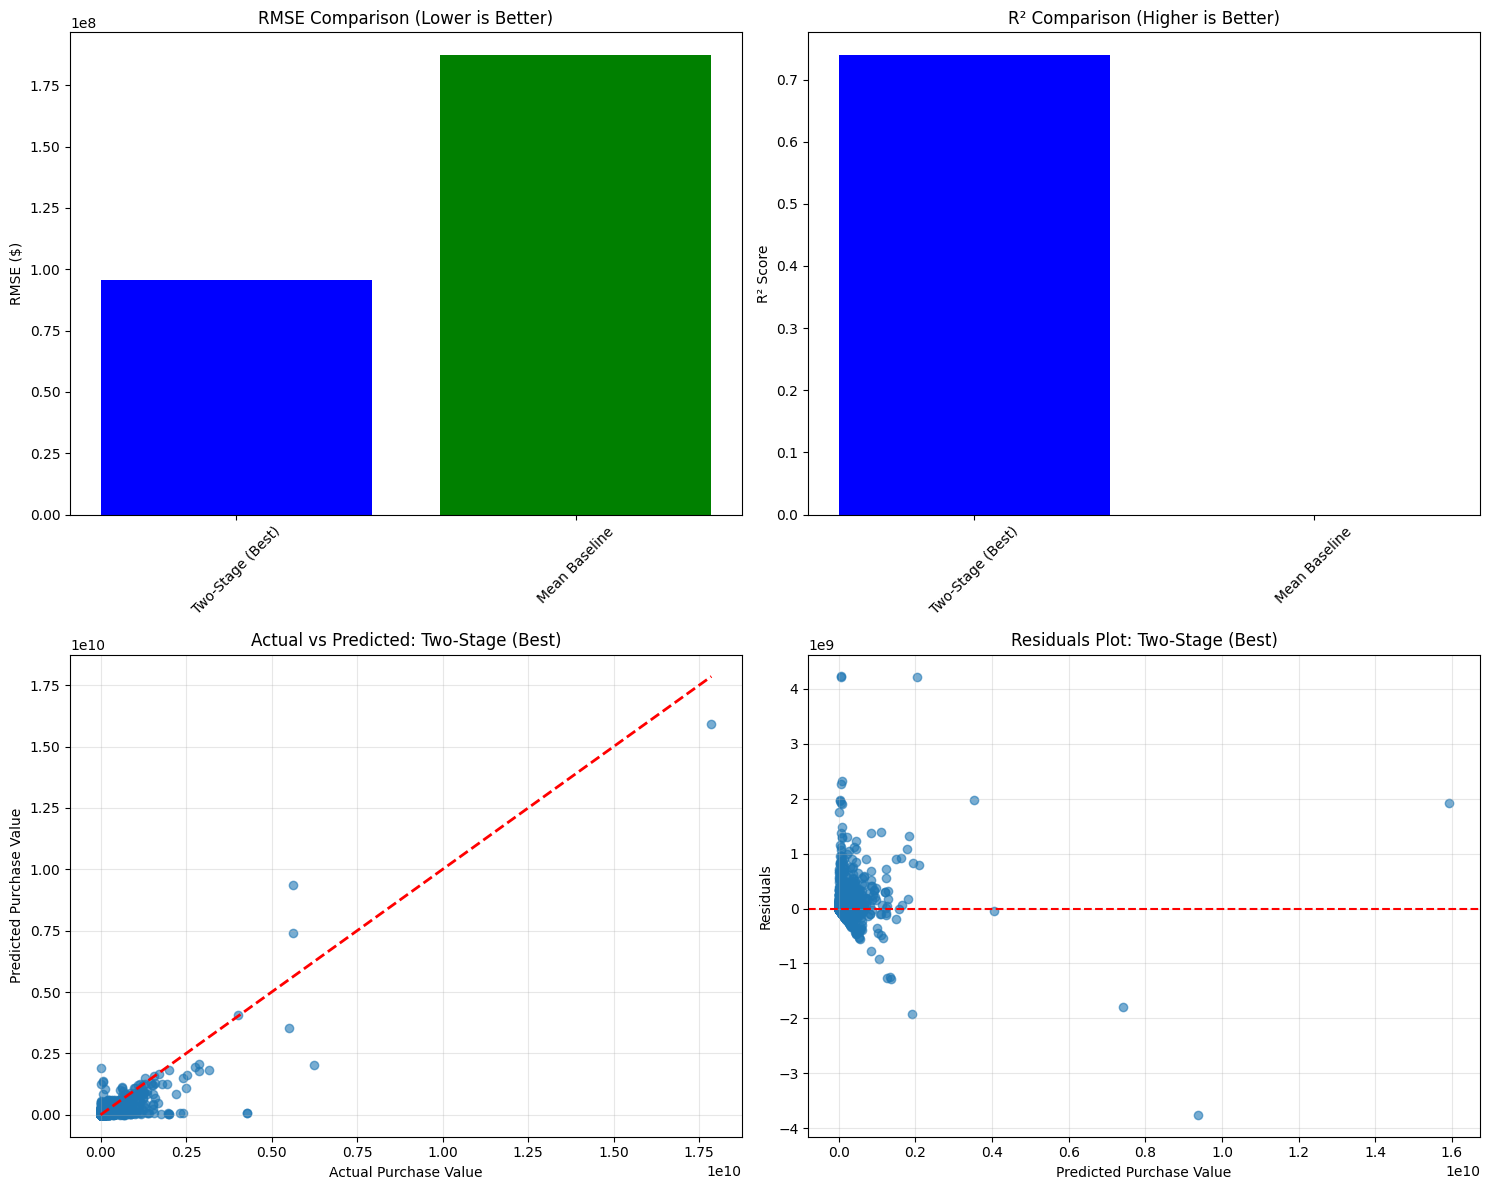

Best model: Two-Stage (Best)
Performance: RMSE=$95679139.29, R²=0.7390


In [21]:
print("\n6. FINAL MODEL COMPARISON")
print("-"*26)

all_results = {
    'Two-Stage (Best)': two_stage_results[best_two_stage],
    'Mean Baseline': {
        'rmse': rmse_baseline,
        'mae': mean_absolute_error(y_test, mean_baseline),
        'r2': r2_score(y_test, mean_baseline),
        'predictions': mean_baseline
    }
}

comparison_df = pd.DataFrame({
    model_name: {
        'RMSE': results['rmse'],
        'MAE': results['mae'],
        'R²': results['r2']
    } for model_name, results in all_results.items()
}).T.sort_values('RMSE')

print("Model Performance Comparison:")
print(comparison_df.round(4))

best_model_name = comparison_df.index[0]
print(f"\nBEST OVERALL MODEL: {best_model_name}")
print(f"   RMSE: ${comparison_df.loc[best_model_name, 'RMSE']:.2f}")
print(f"   R²: {comparison_df.loc[best_model_name, 'R²']:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

models = list(all_results.keys())
rmse_values = [all_results[model]['rmse'] for model in models]
r2_values = [all_results[model]['r2'] for model in models]

axes[0,0].bar(models, rmse_values, color=['blue', 'green', 'orange', 'red'])
axes[0,0].set_title('RMSE Comparison (Lower is Better)')
axes[0,0].set_ylabel('RMSE ($)')
axes[0,0].tick_params(axis='x', rotation=45)

axes[0,1].bar(models, r2_values, color=['blue', 'green', 'orange', 'red'])
axes[0,1].set_title('R² Comparison (Higher is Better)')
axes[0,1].set_ylabel('R² Score')
axes[0,1].tick_params(axis='x', rotation=45)

best_predictions = all_results[best_model_name]['predictions']
axes[1,0].scatter(y_test, best_predictions, alpha=0.6)
axes[1,0].plot([0, y_test.max()], [0, y_test.max()], 'r--', lw=2)
axes[1,0].set_xlabel('Actual Purchase Value')
axes[1,0].set_ylabel('Predicted Purchase Value')
axes[1,0].set_title(f'Actual vs Predicted: {best_model_name}')
axes[1,0].grid(True, alpha=0.3)

residuals = y_test - best_predictions
axes[1,1].scatter(best_predictions, residuals, alpha=0.6)
axes[1,1].axhline(y=0, color='r', linestyle='--')
axes[1,1].set_xlabel('Predicted Purchase Value')
axes[1,1].set_ylabel('Residuals')
axes[1,1].set_title(f'Residuals Plot: {best_model_name}')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Best model: {best_model_name}")
print(f"Performance: RMSE=${comparison_df.loc[best_model_name, 'RMSE']:.2f}, R²={comparison_df.loc[best_model_name, 'R²']:.4f}")


COMPREHENSIVE MODEL COMPARISON: BEFORE vs AFTER TUNING

1. CLASSIFICATION MODELS COMPARISON
----------------------------------------

Classification Models Performance Comparison:
                    Model  Original_F1  Tuned_F1  F1_Improvement  \
0           Random Forest       0.9256    0.9242         -0.0014   
1  Hist Gradient Boosting       0.9275    0.9279          0.0004   
2      XGBoost Classifier       0.9305    0.9314          0.0008   

   Original_Precision  Tuned_Precision  Original_Recall  Tuned_Recall  \
0              0.9039           0.8967           0.9485        0.9535   
1              0.9063           0.9092           0.9498        0.9475   
2              0.9148           0.9141           0.9468        0.9493   

   Training_Time  
0       331.7549  
1       776.7494  
2        58.2851  


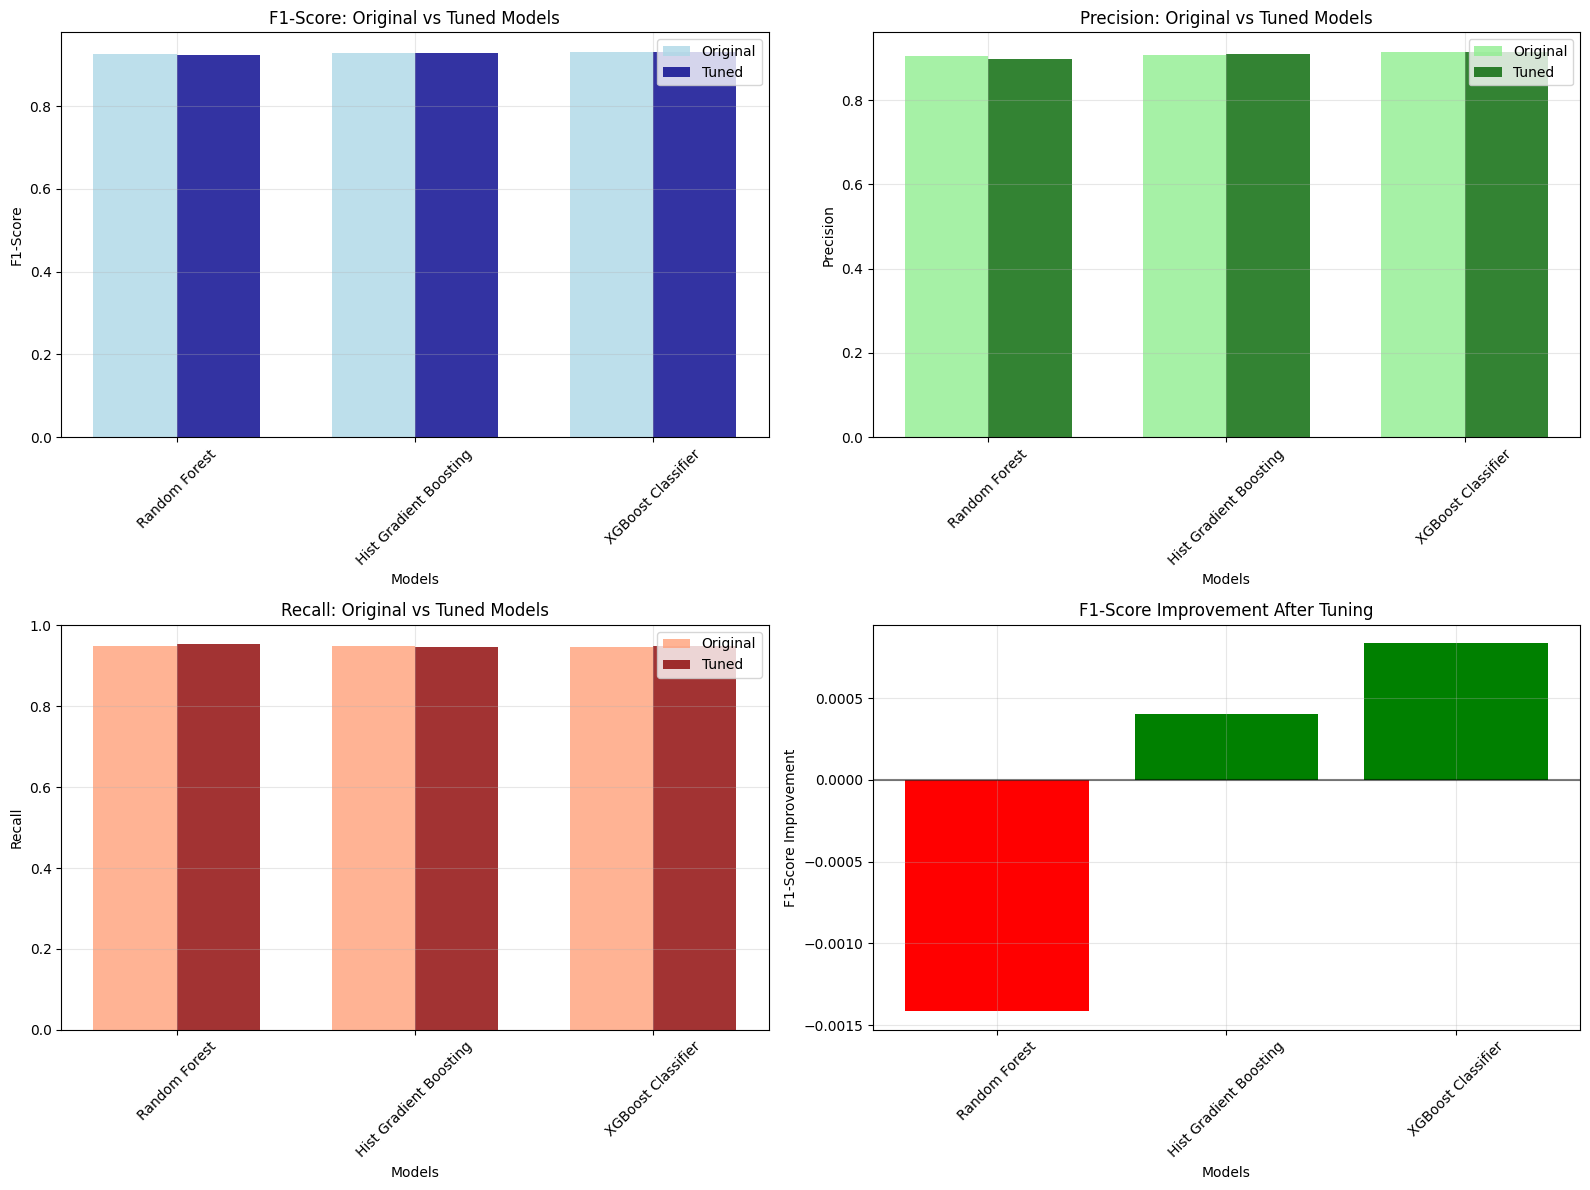


2. REGRESSION MODELS ANALYSIS
--------------------------------

Regression Models Analysis:
                    Model   CV_RMSE  Training_Time  Parameters_Count
0           Random Forest  0.942447     445.198196                 5
1       Gradient Boosting  0.944087     531.644548                 6
2  Hist Gradient Boosting  1.001807      23.760455                 5
3       XGBoost Regressor  0.960604      71.344672                 8
4       Linear Regression       N/A       0.000000                 0

3. FEATURE IMPORTANCE ANALYSIS
---------------------------------

4. TRAINING TIME ANALYSIS
--------------------------

Training Time Comparison:
                                     Model  Training_Time            Type
1  Hist Gradient Boosting (Classification)     776.749423  Classification
4           Gradient Boosting (Regression)     531.644548      Regression
3               Random Forest (Regression)     445.198196      Regression
0           Random Forest (Classification)     331

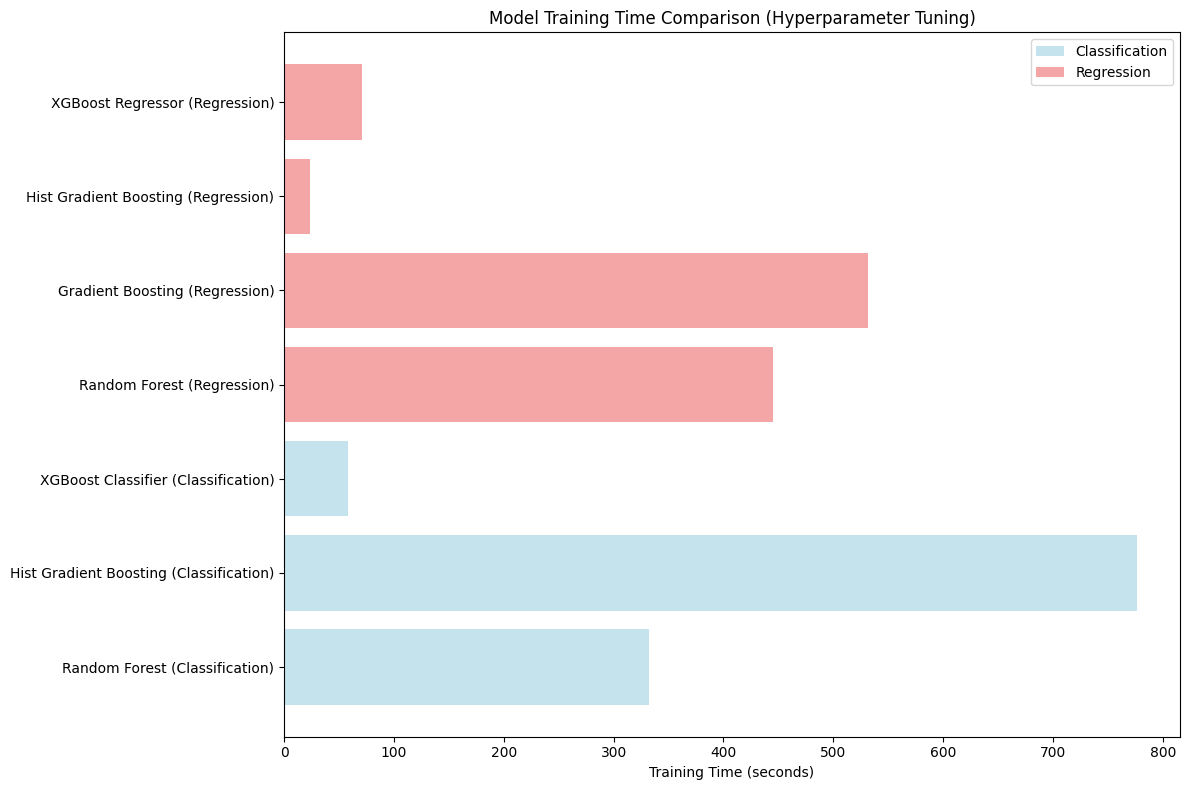


SUMMARY OF MODEL IMPROVEMENTS
 Best Classification Model: XGBoost Classifier
   F1-Score: 0.9314
 Best Regression Model: Random Forest
   CV RMSE: $0.94


In [22]:
print("\n" + "="*70)
print("COMPREHENSIVE MODEL COMPARISON: BEFORE vs AFTER TUNING")
print("="*70)

print("\n1. CLASSIFICATION MODELS COMPARISON")
print("-"*40)

classification_comparison = []

for model_name in ['Random Forest', 'Hist Gradient Boosting', 'XGBoost Classifier']:
    if model_name in classification_results and model_name in tuned_classification_results:
        original = classification_results[model_name]
        tuned = tuned_classification_results[model_name]
        
        classification_comparison.append({
            'Model': model_name,
            'Original_F1': original['f1'],
            'Tuned_F1': tuned['f1'],
            'F1_Improvement': tuned['f1'] - original['f1'],
            'Original_Precision': original['precision'],
            'Tuned_Precision': tuned['precision'],
            'Original_Recall': original['recall'],
            'Tuned_Recall': tuned['recall'],
            'Training_Time': tuned['training_time']
        })

classification_comp_df = pd.DataFrame(classification_comparison)
print("\nClassification Models Performance Comparison:")
print(classification_comp_df.round(4))

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# F1-Score comparison
models = classification_comp_df['Model']
x_pos = np.arange(len(models))
width = 0.35

axes[0,0].bar(x_pos - width/2, classification_comp_df['Original_F1'], width, 
              label='Original', alpha=0.8, color='lightblue')
axes[0,0].bar(x_pos + width/2, classification_comp_df['Tuned_F1'], width, 
              label='Tuned', alpha=0.8, color='darkblue')
axes[0,0].set_xlabel('Models')
axes[0,0].set_ylabel('F1-Score')
axes[0,0].set_title('F1-Score: Original vs Tuned Models')
axes[0,0].set_xticks(x_pos)
axes[0,0].set_xticklabels(models, rotation=45)
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# Precision comparison
axes[0,1].bar(x_pos - width/2, classification_comp_df['Original_Precision'], width, 
              label='Original', alpha=0.8, color='lightgreen')
axes[0,1].bar(x_pos + width/2, classification_comp_df['Tuned_Precision'], width, 
              label='Tuned', alpha=0.8, color='darkgreen')
axes[0,1].set_xlabel('Models')
axes[0,1].set_ylabel('Precision')
axes[0,1].set_title('Precision: Original vs Tuned Models')
axes[0,1].set_xticks(x_pos)
axes[0,1].set_xticklabels(models, rotation=45)
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# Recall comparison
axes[1,0].bar(x_pos - width/2, classification_comp_df['Original_Recall'], width, 
              label='Original', alpha=0.8, color='lightsalmon')
axes[1,0].bar(x_pos + width/2, classification_comp_df['Tuned_Recall'], width, 
              label='Tuned', alpha=0.8, color='darkred')
axes[1,0].set_xlabel('Models')
axes[1,0].set_ylabel('Recall')
axes[1,0].set_title('Recall: Original vs Tuned Models')
axes[1,0].set_xticks(x_pos)
axes[1,0].set_xticklabels(models, rotation=45)
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# F1-Score improvement
axes[1,1].bar(models, classification_comp_df['F1_Improvement'], 
              color=['green' if x > 0 else 'red' for x in classification_comp_df['F1_Improvement']])
axes[1,1].set_xlabel('Models')
axes[1,1].set_ylabel('F1-Score Improvement')
axes[1,1].set_title('F1-Score Improvement After Tuning')
axes[1,1].tick_params(axis='x', rotation=45)
axes[1,1].grid(True, alpha=0.3)
axes[1,1].axhline(y=0, color='black', linestyle='-', alpha=0.5)

plt.tight_layout()
plt.show()

# 3. Regression Models Comparison Analysis
print("\n2. REGRESSION MODELS ANALYSIS")
print("-"*32)

# Create detailed regression comparison
regression_analysis = []
for model_name, model_info in tuned_regression_results.items():
    regression_analysis.append({
        'Model': model_name,
        'CV_RMSE': model_info['best_cv_score'] if model_info['best_cv_score'] else 'N/A',
        'Training_Time': model_info['training_time'],
        'Parameters_Count': len(model_info['best_params'])
    })

regression_analysis_df = pd.DataFrame(regression_analysis)
print("\nRegression Models Analysis:")
print(regression_analysis_df)

# 4. Feature Importance Analysis (for tree-based models)
print("\n3. FEATURE IMPORTANCE ANALYSIS")
print("-"*33)

def get_feature_importance(model, feature_names, model_name):
    """Extract feature importance from trained models"""
    if hasattr(model, 'feature_importances_'):
        importance = model.feature_importances_
        feature_imp_df = pd.DataFrame({
            'feature': feature_names,
            'importance': importance
        }).sort_values('importance', ascending=False)
        return feature_imp_df
    return None

feature_names = (numerical_cols + 
                [f"cat_{i}" for i in range(len(low_cardinality_cats) * 5)] +  # Approximation for one-hot
                high_cardinality_cats)  # Target encoded features

# Feature importance for best regression model
best_reg_model = tuned_regression_results[best_tuned_regressor_name]['model']

# 5. Training Time Analysis
print("\n4. TRAINING TIME ANALYSIS")
print("-"*26)

# Combined training time analysis
all_training_times = []

for model_name, result in tuned_classification_results.items():
    all_training_times.append({
        'Model': f"{model_name} (Classification)",
        'Training_Time': result['training_time'],
        'Type': 'Classification'
    })

for model_name, result in tuned_regression_results.items():
    if result['training_time'] > 0:  # Exclude Linear Regression
        all_training_times.append({
            'Model': f"{model_name} (Regression)",
            'Training_Time': result['training_time'],
            'Type': 'Regression'
        })

training_time_df = pd.DataFrame(all_training_times)
print("\nTraining Time Comparison:")
print(training_time_df.sort_values('Training_Time', ascending=False))

# Plot training times
plt.figure(figsize=(12, 8))
classification_times = training_time_df[training_time_df['Type'] == 'Classification']
regression_times = training_time_df[training_time_df['Type'] == 'Regression']

plt.barh(classification_times['Model'], classification_times['Training_Time'], 
         alpha=0.7, label='Classification', color='lightblue')
plt.barh(regression_times['Model'], regression_times['Training_Time'], 
         alpha=0.7, label='Regression', color='lightcoral')

plt.xlabel('Training Time (seconds)')
plt.title('Model Training Time Comparison (Hyperparameter Tuning)')
plt.legend()
plt.tight_layout()
plt.show()

print(f"\n{'='*70}")
print("SUMMARY OF MODEL IMPROVEMENTS")
print(f"{'='*70}")
print(f" Best Classification Model: {best_tuned_classifier_name}")
print(f"   F1-Score: {tuned_classification_results[best_tuned_classifier_name]['f1']:.4f}")
print(f" Best Regression Model: {best_tuned_regressor_name}")
print(f"   CV RMSE: ${tuned_regression_results[best_tuned_regressor_name]['best_cv_score']:.2f}")
print(f"{'='*70}")


ENSEMBLE METHODS

1. CLASSIFICATION ENSEMBLE
----------------------------
Training ensemble classifier...

ENSEMBLE CLASSIFIER RESULTS:
   Accuracy: 0.9700
   Precision: 0.9076
   Recall: 0.9521
   F1-Score: 0.9293

COMPARISON:
   Best Individual F1: 0.9314
   Ensemble F1: 0.9293
   Improvement: -0.0021

2. REGRESSION ENSEMBLE
-----------------------
Training ensemble regressor...

3. ENSEMBLE TWO-STAGE EVALUATION
-----------------------------------

ENSEMBLE TWO-STAGE RESULTS:
   RMSE: $116767621.28
   MAE: $17077844.53
   R²: 0.6112

4. FINAL MODEL SELECTION
--------------------------

Final Model Comparison:
                                   rmse           mae      r2
Best Individual Two-Stage  9.567914e+07  1.488645e+07  0.7390
Ensemble Two-Stage         1.167676e+08  1.707784e+07  0.6112

FINAL WINNER: Individual Two-Stage Model (XGBoost Classifier + XGBoost Regressor)
   Individual models perform better than ensemble
   Final Best RMSE: $95679139.29


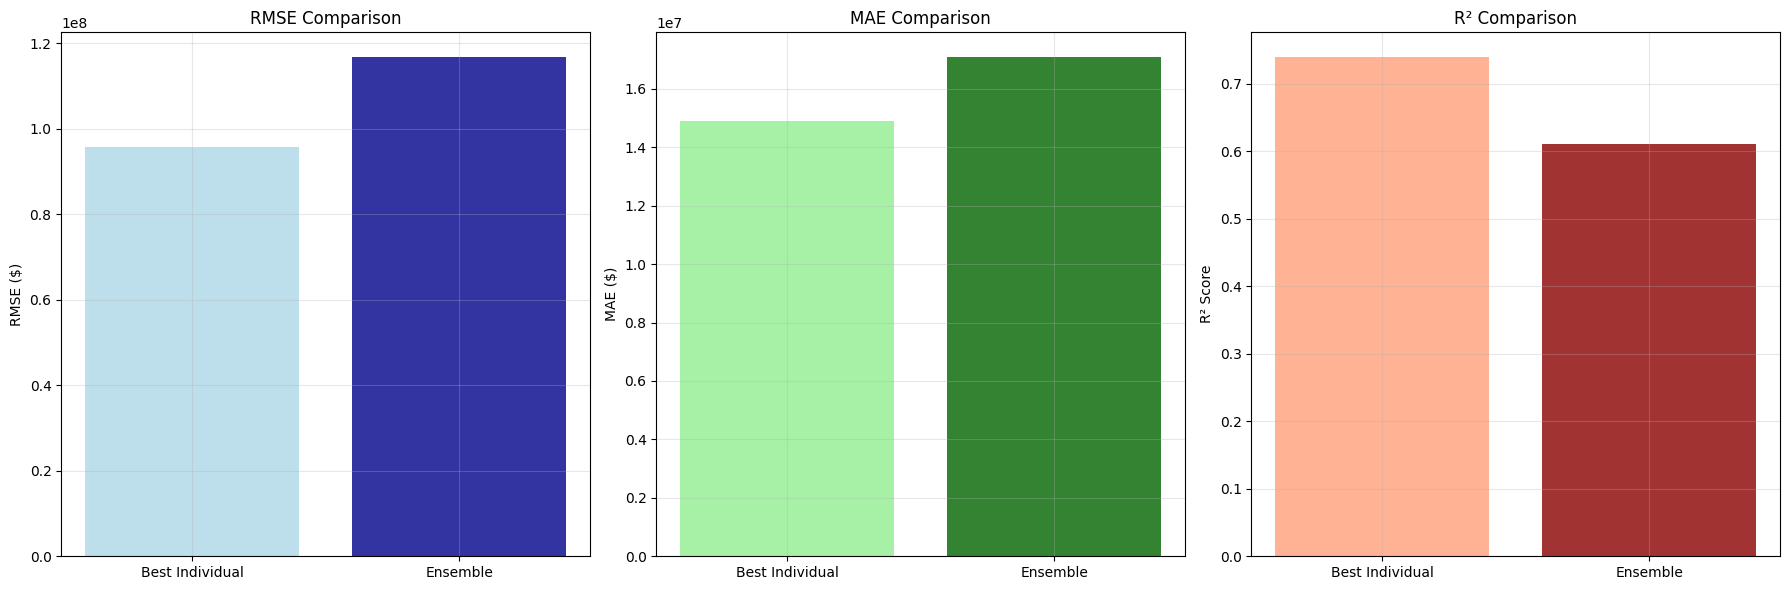

Final best approach selected: Individual


In [23]:
from sklearn.ensemble import VotingClassifier, VotingRegressor
from sklearn.metrics import classification_report

print("\n" + "="*60)
print("ENSEMBLE METHODS")
print("="*60)

print("\n1. CLASSIFICATION ENSEMBLE")
print("-"*28)

top_classifiers = [
    ('rf', tuned_classification_results['Random Forest']['model']),
    ('hist_gb', tuned_classification_results['Hist Gradient Boosting']['model']),
    ('xgb', tuned_classification_results['XGBoost Classifier']['model'])
]

voting_classifier = VotingClassifier(
    estimators=top_classifiers,
    voting='soft'  # Use probability averages
)

print("Training ensemble classifier...")
voting_classifier.fit(X_train_class_processed, y_binary_train)

ensemble_clf_pred = voting_classifier.predict(X_test_class_processed)
ensemble_clf_prob = voting_classifier.predict_proba(X_test_class_processed)[:, 1]

ensemble_clf_accuracy = accuracy_score(y_binary_test, ensemble_clf_pred)
ensemble_clf_precision = precision_score(y_binary_test, ensemble_clf_pred)
ensemble_clf_recall = recall_score(y_binary_test, ensemble_clf_pred)
ensemble_clf_f1 = f1_score(y_binary_test, ensemble_clf_pred)

print("\nENSEMBLE CLASSIFIER RESULTS:")
print(f"   Accuracy: {ensemble_clf_accuracy:.4f}")
print(f"   Precision: {ensemble_clf_precision:.4f}")
print(f"   Recall: {ensemble_clf_recall:.4f}")
print(f"   F1-Score: {ensemble_clf_f1:.4f}")

best_individual_f1 = tuned_classification_results[best_tuned_classifier_name]['f1']
print("\nCOMPARISON:")
print(f"   Best Individual F1: {best_individual_f1:.4f}")
print(f"   Ensemble F1: {ensemble_clf_f1:.4f}")
print(f"   Improvement: {ensemble_clf_f1 - best_individual_f1:.4f}")

print("\n2. REGRESSION ENSEMBLE")
print("-"*23)

top_regressors = [
    ('rf', tuned_regression_results['Random Forest']['model']),
    ('hist_gb', tuned_regression_results['Hist Gradient Boosting']['model']),
    ('xgb', tuned_regression_results['XGBoost Regressor']['model'])
]

voting_regressor = VotingRegressor(estimators=top_regressors)

print("Training ensemble regressor...")
voting_regressor.fit(X_train_reg_processed, y_train_reg_transformed)

print("\n3. ENSEMBLE TWO-STAGE EVALUATION")
print("-"*35)

def evaluate_ensemble_two_stage(clf_ensemble, reg_ensemble, X_test, y_test, 
                               preprocessor_class, preprocessor_reg, use_log=False):
    
    X_test_class_processed = preprocessor_class.transform(X_test)
    purchase_pred = clf_ensemble.predict(X_test_class_processed)
    purchase_prob = clf_ensemble.predict_proba(X_test_class_processed)[:, 1]
    
    final_predictions = np.zeros(len(y_test))
    
    if np.sum(purchase_pred) > 0:
        X_test_purchase = X_test[purchase_pred == 1]
        X_test_reg_processed = preprocessor_reg.transform(X_test_purchase)
        
        amount_pred = reg_ensemble.predict(X_test_reg_processed)
        
        if use_log:
            amount_pred = np.expm1(amount_pred)
        
        amount_pred = np.maximum(amount_pred, 0)
        final_predictions[purchase_pred == 1] = amount_pred
    
    return final_predictions, purchase_pred, purchase_prob

ensemble_final_pred, ensemble_purchase_pred, ensemble_purchase_prob = evaluate_ensemble_two_stage(
    voting_classifier, voting_regressor, X_test, y_test,
    preprocessor_classification, preprocessor_regression, use_log=use_log_transform
)

ensemble_rmse = np.sqrt(mean_squared_error(y_test, ensemble_final_pred))
ensemble_mae = mean_absolute_error(y_test, ensemble_final_pred)
ensemble_r2 = r2_score(y_test, ensemble_final_pred)

print("\nENSEMBLE TWO-STAGE RESULTS:")
print(f"   RMSE: ${ensemble_rmse:.2f}")
print(f"   MAE: ${ensemble_mae:.2f}")
print(f"   R²: {ensemble_r2:.4f}")

ensemble_results = {
    'predictions': ensemble_final_pred,
    'rmse': ensemble_rmse,
    'mae': ensemble_mae,
    'r2': ensemble_r2,
    'purchase_predictions': ensemble_purchase_pred,
    'purchase_probabilities': ensemble_purchase_prob
}

print("\n4. FINAL MODEL SELECTION")
print("-"*26)

model_comparison = {
    'Best Individual Two-Stage': {
        'rmse': two_stage_results[best_two_stage]['rmse'],
        'mae': two_stage_results[best_two_stage]['mae'],
        'r2': two_stage_results[best_two_stage]['r2']
    },
    'Ensemble Two-Stage': {
        'rmse': ensemble_rmse,
        'mae': ensemble_mae,
        'r2': ensemble_r2
    }
}

comparison_summary = pd.DataFrame(model_comparison).T
print("\nFinal Model Comparison:")
print(comparison_summary.round(4))

if ensemble_rmse < two_stage_results[best_two_stage]['rmse']:
    final_best_approach = "Ensemble"
    final_best_rmse = ensemble_rmse
    print(f"   RMSE Improvement: ${two_stage_results[best_two_stage]['rmse'] - ensemble_rmse:.2f}")
    
    best_classifier = voting_classifier
    best_classifier_name = "Ensemble Classifier"
    regression_results[best_two_stage] = voting_regressor
else:
    final_best_approach = "Individual"
    final_best_rmse = two_stage_results[best_two_stage]['rmse']
    print(f"\nFINAL WINNER: Individual Two-Stage Model ({best_tuned_classifier_name} + {best_two_stage})")
    print(f"   Individual models perform better than ensemble")

print(f"   Final Best RMSE: ${final_best_rmse:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

models = ['Best Individual', 'Ensemble']
rmse_values = [two_stage_results[best_two_stage]['rmse'], ensemble_rmse]
mae_values = [two_stage_results[best_two_stage]['mae'], ensemble_mae]
r2_values = [two_stage_results[best_two_stage]['r2'], ensemble_r2]

axes[0].bar(models, rmse_values, color=['lightblue', 'darkblue'], alpha=0.8)
axes[0].set_ylabel('RMSE ($)')
axes[0].set_title('RMSE Comparison')
axes[0].grid(True, alpha=0.3)

axes[1].bar(models, mae_values, color=['lightgreen', 'darkgreen'], alpha=0.8)
axes[1].set_ylabel('MAE ($)')
axes[1].set_title('MAE Comparison')
axes[1].grid(True, alpha=0.3)

# R² comparison
axes[2].bar(models, r2_values, color=['lightsalmon', 'darkred'], alpha=0.8)
axes[2].set_ylabel('R² Score')
axes[2].set_title('R² Comparison')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Final best approach selected: {final_best_approach}")

# Final Predicition

In [24]:
print("\n" + "="*60)
print("PREDICTION ON TEST DATA AND SUBMISSION")
print("="*60)

test_df = pd.read_csv('/kaggle/input/engage-2-value-from-clicks-to-conversions/test_data.csv')
print(f"Test data shape: {test_df.shape}")
print(f"Test data columns: {test_df.columns.tolist()}")

print("\n2. PREPROCESSING TEST DATA")
print("-"*28)

X_test_final = create_new_cols(test_df)

X_test_final = drop_columns(X_test_final)

test_ids = pd.Series(range(len(X_test_final)), name='id')

print(f"Final test features shape: {X_test_final.shape}")


print("\n3. MAKING PREDICTIONS WITH BEST MODEL")
print("-"*40)

print(f"Using best model: {best_classifier_name} + {best_two_stage}")

X_test_class_processed = preprocessor_classification.transform(X_test_final)
purchase_predictions = best_classifier.predict(X_test_class_processed)
purchase_probabilities = best_classifier.predict_proba(X_test_class_processed)[:, 1]

print("Classification completed:")
print(f"  Predicted purchases: {np.sum(purchase_predictions):,}")
print(f"  Predicted non-purchases: {np.sum(purchase_predictions == 0):,}")
print(f"  Purchase rate: {np.mean(purchase_predictions):.3f}")

final_test_predictions = np.zeros(len(X_test_final))

if np.sum(purchase_predictions) > 0:
    X_test_purchase = X_test_final[purchase_predictions == 1]
    X_test_reg_processed = preprocessor_regression.transform(X_test_purchase)
    
    best_regressor = regression_results[best_two_stage]
    amount_predictions = best_regressor.predict(X_test_reg_processed)
    
    if use_log_transform:
        amount_predictions = np.expm1(amount_predictions)
    
    amount_predictions = np.maximum(amount_predictions, 0)
    
    final_test_predictions[purchase_predictions == 1] = amount_predictions
    
    print(f"  Non-zero predictions: {np.sum(final_test_predictions > 0):,}")
    print(f"  Average predicted amount: ${np.mean(amount_predictions):,.2f}")
    print(f"  Max predicted amount: ${np.max(amount_predictions):,.2f}")
    print(f"  Min predicted amount: ${np.min(amount_predictions):,.2f}")

else:
    print("No purchases predicted by classification model")

submission_df = pd.DataFrame({
    'id': test_ids,
    'purchaseValue': final_test_predictions
})

submission_filename = 'submission.csv'
submission_df.to_csv(submission_filename, index=False)


PREDICTION ON TEST DATA AND SUBMISSION
Test data shape: (29006, 51)
Test data columns: ['userChannel', 'date', 'browser', 'device.browserSize', 'device.browserVersion', 'deviceType', 'device.flashVersion', 'device.isMobile', 'device.language', 'device.mobileDeviceBranding', 'device.mobileDeviceMarketingName', 'device.mobileDeviceModel', 'device.mobileInputSelector', 'os', 'device.operatingSystemVersion', 'device.screenColors', 'device.screenResolution', 'geoNetwork.city', 'geoNetwork.continent', 'locationCountry', 'geoNetwork.metro', 'geoNetwork.networkDomain', 'geoNetwork.networkLocation', 'geoNetwork.region', 'geoNetwork.subContinent', 'socialEngagementType', 'totals.bounces', 'totalHits', 'new_visits', 'pageViews', 'totals.visits', 'trafficSource.adContent', 'trafficSource.adwordsClickInfo.adNetworkType', 'trafficSource.adwordsClickInfo.isVideoAd', 'trafficSource.adwordsClickInfo.page', 'trafficSource.adwordsClickInfo.slot', 'trafficSource.campaign', 'trafficSource.isTrueDirect', '